# Tracking giocatori e numeri di maglia: YOLO + ByteTrack + OCR locale

Detection e tracking multi-oggetto, senza riaddestramento. Usa il checkpoint giocatori locale e solo la classe `player`, non `refree`. Una baseline COCO `person` e ammessa solo con consenso esplicito in configurazione e puo includere arbitri/pubblico. Non riconosce identita fisiche, squadre o ruoli. Gli ID sono temporanei; il numero letto e una memoria per ID, non re-identificazione. Un ID switch puo associare il numero sbagliato alla persona subentrata.

**Limite restituito: massimo 6 ID per meta, quindi massimo 12 per frame** (`ENABLE_SIDE_CAP=True`). Non vengono inventati individui per raggiungere 12: possono essercene meno, e gli ID storici non sono il numero di persone nel frame. Le meta A=Y<9m e B=Y>=9m sono stime geometriche dei piedi, anche oltre i fondocampo, NON identita di squadra/maglia; Y=9 appartiene solo a B. Dopo il filtro sinistro si candidano soltanto track associate a detection correnti, non predizioni perse o box senza ID. Se una meta supera 6, precedenza agli ID gia ammessi nel frame precedente **sulla stessa meta attuale**, poi confidence YOLO corrente decrescente, anzianita della track in update decrescente, infine ID crescente. Non si penalizza un ID consolidato per una singola nuova confidence piu alta. Un cambio lato segue i piedi correnti, viene registrato e perde priorita sul vecchio lato; non si trasferiscono ID all'altra meta per riempire posti. Dopo un frame senza osservazione la priorita precedente termina. Il cap non classifica giocatori veri, non elimina duplicati garantiti, non corregge la calibrazione e puo scartare un atleta a favore di un falso positivo gia stabile. Accuratezza/ID switches richiedono GT, qui non disponibili.

Il cap richiede `ROI_MODE='floor'` e H pavimento valida. Per image/none occorre disabilitare **esplicitamente** `ENABLE_SIDE_CAP=False`, rinunciando alla garanzia6/12; nessuna assegnazione squadra fittizia in assenza di coordinate. Il parametro `EXPECTED_PLAYERS=12` resta diagnostica, non obiettivo minimo.

ByteTrack di Ultralytics contiene gia un Kalman interno: non ne aggiungiamo un altro. Il notebook mantiene **una sola istanza BYTETracker** per tutta la clip (persistenza esplicita, equivalente allo scopo di `persist=True`, senza callback che possano azzerarla ogni frame). Ogni update corrisponde a stride/FPS secondi video; velocita interne sono per frame campionato. Un nuovo avvio della cella crea una run e tracker nuovi. Con `FRAME_STRIDE=1`, seek iniziale e decodifica sequenziale verificata; con stride>1, seek verificato a ogni campione. Stride elevati riducono la qualita delle associazioni: preferire 1.

Per il campo si usa soltanto l'omografia del pavimento, mai la camera 3D fallita: piede approssimato = centro del bordo inferiore della bbox YOLO. Salti/occlusioni/box imprecisi rendono questa stima incerta. ROI opzionale: `floor` (default con calibrazione coerente), `image` (poligono manuale) oppure `none` (nessun filtro esplicito). Nessuna calibrazione viene modificata.

**Filtro temporale, solo bordo sinistro in modalita floor:** ByteTrack associa prima tutte le detection player con piedi validi nell'immagine. Solo **X < -COURT_MARGIN_M**, cioe X < -0.25m, incrementa il contatore per ID. X=0 e il bordo sinistro (verificato con calibrazione e proiezioni a Y=0,9,18m). `MAX_OUTSIDE_COURT_UPDATES=10` mantiene le prime 9 osservazioni fuori a sinistra, poi esclude l'ID da video, conteggio attivo e CSV principale. A stride1/30fps sono circa0.33s video. **X >= -0.25m azzera il contatore e riabilita anche un ID gia escluso.** Bordo destro e fondocampo non provocano esclusione, anche se il punto e fuori dal rettangolo9x18m: non e un filtro globale in campo. Gap senza detection interrompe la consecutivita; geometria non valida non prova permanenza fuori e non produce osservazioni ammesse. Dopo soglia l'ID resta soppresso finche non rientra dal lato sinistro o scade nel tracker. La traccia interna non viene eliminata, per non ricreare subito un ID; nuovi ID possono comunque riavviare la tolleranza. `image` mantiene la precedente regola sull'intero poligono (esclusione fino scadenza ID), `none` la disattiva. Non e un classificatore allenatore: staff entro margine puo restare e atleti fuori a sinistra a lungo possono essere esclusi. Salti/occlusioni/box imprecisi rendono i piedi approssimati.

Gli output salvati nelle celle e nelle vecchie run sono storici e NON cambiano con questo codice. Dopo aver riaperto il notebook aggiornato dal disco, riavvia il kernel ed esegui tutte le celle; per floor verifica nella nuova `configurazione.json` margine0.25 e `outside_gate_version=post_association_left_sideline_only_v3`.

**Nuova funzione: numero maglia.** EasyOCR locale tenta la lettura su ogni crop torso valido di ogni track ammessa e osservata, raggruppando le immagini del singolo frame con `readtext_batched` e conservando il mapping posizione→ID. Letture multiple confermano il valore; in caso di mancata lettura si conserva il numero per lo stesso ID, mentre una contraddizione singola non lo sovrascrive. Il numero non viene trasferito a nuovi ID. Le uscite Tesseract già incorporate nelle celle e la run 2026-11-18 restano storiche: non sono risultati EasyOCR. Il nuovo preflight richiede pesi EasyOCR locali verificati e non scarica modelli durante il tracking.

In [24]:
import os
os.environ['YOLO_AUTOINSTALL'] = 'false'  # prima di ogni import Ultralytics: nessuna installazione automatica
import importlib.util
import inspect
import json
import math
import time
import hashlib
import re
import shutil
from collections import deque
import sys
from pathlib import Path
from datetime import datetime
from types import SimpleNamespace
from uuid import uuid4

WORKSPACE_DIR = next((p.resolve() for p in (Path.cwd(), *Path.cwd().parents)
                      if (p / 'Annotazioni').is_dir() and (p / 'runs').is_dir()), None)
if WORKSPACE_DIR is None:
    raise FileNotFoundError('Avvia il notebook dalla cartella Scout_Volley_CV&NLP o da una sua sottocartella.')
CHECKPOINTS = sorted((WORKSPACE_DIR / 'runs' / 'volleyball_players').glob('**/weights/best.pt'))
VIDEOS = sorted(p for p in (WORKSPACE_DIR / 'Annotazioni').iterdir()
                if p.suffix.lower() in {'.mp4', '.avi', '.mov', '.mkv'})
for i, p in enumerate(CHECKPOINTS, 1):
    print('Checkpoint', i, p.relative_to(WORKSPACE_DIR))
for i, p in enumerate(VIDEOS, 1):
    print('Video', i, p.relative_to(WORKSPACE_DIR))

CHECKPOINT_INDEX = 1 if len(CHECKPOINTS) == 1 else None
VIDEO_INDEX = 3
ALLOW_COCO_BASELINE = False  # solo se mancano pesi giocatori; person include arbitri/spettatori
COCO_WEIGHTS_PATH = WORKSPACE_DIR / 'yolov8m.pt'
START_SECONDS, END_SECONDS = 680, 7350
FRAME_STRIDE = 1
IMAGE_SIZE = 640
DETECTION_CONFIDENCE = 0.10  # basso per il secondo stadio ByteTrack
DISPLAY_CONFIDENCE = 0.40  # conteggio detection affidabili e box non ancora associati
NMS_IOU = 0.50
MAX_DETECTIONS = 100  # NON top12
TRACK_HIGH_THRESHOLD = 0.40
NEW_TRACK_THRESHOLD = 0.40
TRACK_LOST_SECONDS = 1.0
MATCH_THRESHOLD = 0.80
REQUEST_GPU = True
EXPECTED_PLAYERS = 12
EXPECTED_PER_HALF = 6
ENABLE_SIDE_CAP = True  # massimo 6 ID per meta/12 totali; richiede ROI_MODE=floor e omografia valida
ROI_MODE = 'floor'  # floor | image | none: scelta esplicita, nessun fallback silenzioso
COURT_MARGIN_M = 0.25  # tolleranza metrica oltre linee campo; nessun clamp delle coordinate
MAX_OUTSIDE_COURT_UPDATES = 10  # esclusione al decimo campione consecutivo fuori ROI, non dieci frame sorgente
IMAGE_ROI_POINTS = None  # solo ROI_MODE='image': lista di vertici [x_px, y_px]
CALIBRATION_PATH = None  # None cerca solo il file con nome del video selezionato
SAMPLE_INTERVAL_SECONDS = 1.0
MAX_SAMPLES = 3
MAX_CLIP_SECONDS = 1e8

# EasyOCR locale: Reader persistente, pesi gia presenti, nessun download in una run normale.
EASYOCR_MODEL_DIR = Path.home() / '.EasyOCR' / 'model'
EASYOCR_FRAME_BATCH_SIZE = 12  # un crop per track ammessa osservata nel frame; max 12 per il cap
EASYOCR_RECOGNITION_BATCH_SIZE = 4
EASYOCR_ALLOWLIST = '0123456789'
OCR_LANGUAGE = 'eng'
JERSEY_NUMBER_MIN = 0
JERSEY_NUMBER_MAX = 99  # configurabile, nessun roster specifico presunto
OCR_MIN_CONFIDENCE = 25.0  # confidence EasyOCR 0..100, distinta da confidence YOLO
OCR_CONSENSUS_WINDOW = 5  # tentativi OCR recenti per ID, uno per osservazione/frame
OCR_MIN_VOTES = 3  # letture uguali necessarie per confermare/cambiare numero
OCR_CROP_FRACTION = (0.12, 0.18, 0.88, 0.68)  # torso centrale relativo alla bbox
MAX_SAVED_JERSEY_CROPS = 24  # campioni diagnostici, non limita le chiamate OCR

def select_file(paths, index, label):
    if index is None or isinstance(index, bool) or not isinstance(index, int) or not 1 <= index <= len(paths):
        raise ValueError(f'Seleziona {label}_INDEX tra 1 e {len(paths)} dopo aver letto la lista.')
    return paths[index-1].resolve()

if CHECKPOINTS:
    CHECKPOINT_PATH = select_file(CHECKPOINTS, CHECKPOINT_INDEX, 'CHECKPOINT')
    MODEL_SOURCE = 'fine_tuned_players'
elif ALLOW_COCO_BASELINE:
    CHECKPOINT_PATH = Path(COCO_WEIGHTS_PATH).resolve()
    MODEL_SOURCE = 'explicit_COCO_person_baseline'
    print('ATTENZIONE: baseline COCO person, non modello fine-tuned giocatori.')
else:
    raise FileNotFoundError('Checkpoint giocatori assente. Completa fine-tuning oppure scegli esplicitamente ALLOW_COCO_BASELINE=True.')
VIDEO_PATH = select_file(VIDEOS, VIDEO_INDEX, 'VIDEO')
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f'Checkpoint locale mancante: {CHECKPOINT_PATH}; nessun download automatico.')
if not all(math.isfinite(x) for x in (START_SECONDS, END_SECONDS, TRACK_LOST_SECONDS, COURT_MARGIN_M, SAMPLE_INTERVAL_SECONDS, OCR_MIN_CONFIDENCE)):
    raise ValueError('Tempi, margine e intervallo sample devono essere finiti.')
if not math.isfinite(MAX_CLIP_SECONDS) or MAX_CLIP_SECONDS <= 0:
    raise ValueError('MAX_CLIP_SECONDS deve essere finito e positivo; non cambia END_SECONDS.')
if not 0 <= START_SECONDS < END_SECONDS or END_SECONDS-START_SECONDS > MAX_CLIP_SECONDS:
    raise ValueError(f'Imposta un estratto positivo non oltre {MAX_CLIP_SECONDS}s.')
if isinstance(FRAME_STRIDE, bool) or not isinstance(FRAME_STRIDE, int) or FRAME_STRIDE < 1:
    raise ValueError('FRAME_STRIDE deve essere un intero positivo.')
if not 0 < DETECTION_CONFIDENCE < TRACK_HIGH_THRESHOLD <= NEW_TRACK_THRESHOLD <= 1:
    raise ValueError('Richiesto 0 < conf bassa < track_high <= new_track <= 1.')
if not DETECTION_CONFIDENCE <= DISPLAY_CONFIDENCE <= 1 or not 0 < NMS_IOU <= 1 or not 0 < MATCH_THRESHOLD <= 1:
    raise ValueError('Soglie confidence/NMS/matching non valide.')
if TRACK_LOST_SECONDS < 0 or COURT_MARGIN_M < 0 or SAMPLE_INTERVAL_SECONDS <= 0 or MAX_SAMPLES < 1:
    raise ValueError('Timeout/margine non negativi e intervallo/numero sample positivi richiesti.')
if isinstance(JERSEY_NUMBER_MIN, bool) or isinstance(JERSEY_NUMBER_MAX, bool) or not isinstance(JERSEY_NUMBER_MIN, int) or not isinstance(JERSEY_NUMBER_MAX, int) or not 0 <= JERSEY_NUMBER_MIN <= JERSEY_NUMBER_MAX <= 99:
    raise ValueError('Intervallo numeri maglia non valido: interi 0..99.')
if not 0 <= OCR_MIN_CONFIDENCE <= 100 or not isinstance(OCR_CONSENSUS_WINDOW, int) or isinstance(OCR_CONSENSUS_WINDOW, bool) or not 1 <= OCR_MIN_VOTES <= OCR_CONSENSUS_WINDOW or MAX_SAVED_JERSEY_CROPS < 0:
    raise ValueError('Parametri di OCR/voto/crop non validi.')
if any(isinstance(v,bool) or not isinstance(v,int) or v<1 for v in (EASYOCR_FRAME_BATCH_SIZE,EASYOCR_RECOGNITION_BATCH_SIZE)):
    raise ValueError('Dimensioni batch EasyOCR devono essere interi positivi.')
if isinstance(MAX_OUTSIDE_COURT_UPDATES, bool) or not isinstance(MAX_OUTSIDE_COURT_UPDATES, int) or MAX_OUTSIDE_COURT_UPDATES < 1:
    raise ValueError('MAX_OUTSIDE_COURT_UPDATES deve essere un intero positivo.')
if not isinstance(ENABLE_SIDE_CAP, bool):
    raise ValueError('ENABLE_SIDE_CAP deve essere True o False esplicito.')
if ENABLE_SIDE_CAP and ROI_MODE != 'floor':
    raise ValueError('Cap 6 per meta richiede ROI_MODE=floor. Per image/none disabilita esplicitamente ENABLE_SIDE_CAP=False (nessun limite garantito).')
if ROI_MODE not in {'floor', 'image', 'none'}:
    raise ValueError('ROI_MODE deve essere floor, image oppure none.')
print('Video:', VIDEO_PATH, '\nModello:', CHECKPOINT_PATH)

Checkpoint 1 runs\volleyball_players\yolov8m_players_20261117_083439\weights\best.pt
Video 1 Annotazioni\ITA_POL_VNL2024_30fps.mp4
Video 2 Annotazioni\ITA_SRB_Parigi2024_30fps.mp4
Video 3 Annotazioni\Test_demo_ITA_DOM_Parigi2024_30fps.mp4
Video: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Annotazioni\Test_demo_ITA_DOM_Parigi2024_30fps.mp4 
Modello: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players\yolov8m_players_20261117_083439\weights\best.pt


## EasyOCR locale, modelli e dispositivo

Il backend corrente e EasyOCR 1.7.2 locale. Il preflight crea una sola istanza persistente del reader English, verifica i file modello e usa la stessa CUDA selezionata dal detector; se uno dei modelli o il runtime GPU manca, si ferma con errore esplicito, senza fallback OCR silenzioso o download durante l'esecuzione.

Compatibilita verificata nell'interprete Python 3.14.6: `easyocr==1.7.2`, `torch==2.14.1+cu130`, `torchvision==0.29.1+cu130`, `numpy==2.5.0`, `scipy==1.18.0`, `opencv-python==5.0.0.93`, `scikit-image==0.26.0`, `python-bidi==0.6.12`, `pyclipper==1.4.0`, `ninja==1.13.2`, `imageio==2.38.2`, `tifffile==2026.11.16`, `lazy-loader==0.6`. `torch`/`torchvision` GPU e OpenCV gia presenti sono stati mantenuti; `opencv-python-headless` non e stato installato per evitare conflitti con `cv2`. Le dipendenze EasyOCR mancanti sono state installate con `pip --no-deps` dopo un resolver dry-run Python 3.14. I pacchetti non vengono installati dal notebook.

Pesi official EasyOCR in `%USERPROFILE%\.EasyOCR\model` (modificabile con `EASYOCR_MODEL_DIR`): `craft_mlt_25k.pth` (MD5 `2f8227d2def4037cdb3b34389dcf9ec1`) e `english_g2.pth` (MD5 `5864788e1821be9e454ec108d61b887d`). In questo ambiente sono stati ottenuti dai release ufficiali con HTTPS verificato e il trust store di `curl.exe`, poi controllati contro gli hash dichiarati da EasyOCR. Python `urllib` non ha potuto scaricarli per un errore TLS del certificato aziendale; non e stata disabilitata la verifica. `download_enabled=False` impedisce download automatici in tutte le run. Se i modelli mancano in un altro ambiente, scaricali esplicitamente dai link ufficiali nella configurazione, estrai i due `.pth` nella cartella e controlla i checksum; il notebook non prova a riparare TLS.

Ultralytics ha autoinstall disabilitato prima degli import. NMS CPU e CUDA vengono testate; solo la specifica NMS CUDA non implementata provoca fallback CPU. EasyOCR usa `readtext_batched` solo per crop torso di uguali dimensioni, li inserisce nell'ordine degli ID e verifica un gruppo di risultati per ogni crop. L'allowlist ammette cifre; non si inviano immagini a servizi remoti. Nessun bypass TLS.


In [25]:
missing = [name for name in ('torch', 'torchvision', 'ultralytics', 'cv2', 'numpy', 'lap')
           if importlib.util.find_spec(name) is None]
if missing:
    raise ModuleNotFoundError(f'Dipendenze tracking mancanti: {missing}. Kernel: {sys.executable}. Installa solo opt-in in ambiente isolato e riavvia.')
if importlib.util.find_spec('easyocr') is None:
    raise ModuleNotFoundError(f'EasyOCR non disponibile nel kernel {sys.executable}. Installa easyocr==1.7.2 e dipendenze in questo ambiente, poi riavvia; nessuna installazione automatica.')
import torch
import numpy as np
import cv2
import easyocr
EASYOCR_MODEL_DIR = Path(EASYOCR_MODEL_DIR).expanduser().resolve()
EASYOCR_MODEL_MD5 = {'craft_mlt_25k.pth':'2f8227d2def4037cdb3b34389dcf9ec1','english_g2.pth':'5864788e1821be9e454ec108d61b887d'}
def file_md5(path):
    digest=hashlib.md5()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()
if not EASYOCR_MODEL_DIR.is_dir():
    raise FileNotFoundError(f'Cartella pesi EasyOCR mancante: {EASYOCR_MODEL_DIR}. Scarica esplicitamente i modelli ufficiali; il notebook non abilita download automatici.')
for model_name,expected_md5 in EASYOCR_MODEL_MD5.items():
    model_path=EASYOCR_MODEL_DIR/model_name
    if not model_path.is_file(): raise FileNotFoundError(f'Peso EasyOCR mancante: {model_path}. Prepara i modelli prima di eseguire il tracking.')
    actual_md5=file_md5(model_path)
    if actual_md5!=expected_md5: raise RuntimeError(f'Checksum EasyOCR non valido per {model_path}: {actual_md5}')
import torchvision
import ultralytics
from ultralytics import YOLO
from ultralytics.utils import AUTOINSTALL
if AUTOINSTALL:
    raise RuntimeError('Ultralytics era gia importato con autoinstall attivo. Riavvia kernel e riesegui dal principio; nessuna installazione viene richiesta qui.')
from ultralytics.trackers.byte_tracker import BYTETracker
import torchvision

def nms_preflight(device):
    boxes = torch.tensor([[0.,0.,10.,10.],[1.,1.,11.,11.]], device=device)
    scores = torch.tensor([0.9,0.8], device=device)
    if torchvision.ops.nms(boxes, scores, 0.5).tolist() != [0]:
        raise RuntimeError(f'NMS inattesa su {device}')
nms_preflight('cpu')
DEVICE = 'cpu'
if REQUEST_GPU and torch.cuda.is_available():
    try:
        nms_preflight('cuda:0')
    except NotImplementedError as exc:
        if 'torchvision::nms' not in str(exc) or 'CUDA' not in str(exc):
            raise
        print('NMS CUDA non implementata: fallback CPU esplicito.')
    else:
        DEVICE = 0
else:
    print(f'Fallback CPU esplicito; CUDA richiesta={REQUEST_GPU}, disponibile={torch.cuda.is_available()}, build={torch.version.cuda}.')
print(f'Python {sys.executable}; torch={torch.__version__}; torchvision={torchvision.__version__}; ultralytics={ultralytics.__version__}; device={DEVICE}')
EASYOCR_DEVICE = 'cpu' if DEVICE == 'cpu' else f'cuda:{DEVICE}'
EASYOCR_READER = easyocr.Reader(['en'],gpu=EASYOCR_DEVICE,model_storage_directory=str(EASYOCR_MODEL_DIR),download_enabled=False,verbose=False,quantize=False)
if str(EASYOCR_READER.device) != EASYOCR_DEVICE:
    raise RuntimeError(f'EasyOCR ha selezionato {EASYOCR_READER.device!r}, richiesto esplicitamente {EASYOCR_DEVICE!r}; nessun fallback silenzioso.')
for model_name,model in [('detector',EASYOCR_READER.detector),('recognizer',EASYOCR_READER.recognizer)]:
    model_devices={parameter.device.type for parameter in model.parameters()}
    if model_devices != {EASYOCR_DEVICE.split(':')[0]}:
        raise RuntimeError(f'EasyOCR {model_name} su device inatteso: {model_devices}; atteso {EASYOCR_DEVICE}.')
probe_image=np.full((120,220,3),255,dtype=np.uint8)
cv2.putText(probe_image,'12',(12,96),cv2.FONT_HERSHEY_SIMPLEX,2.7,(0,0,0),6,cv2.LINE_AA)
probe_results=EASYOCR_READER.readtext_batched([probe_image],n_width=220,n_height=120,detail=1,paragraph=False,allowlist=EASYOCR_ALLOWLIST,decoder='greedy',batch_size=EASYOCR_RECOGNITION_BATCH_SIZE,workers=0)
if len(probe_results)!=1 or not any(str(item[1]).strip()=='12' for item in probe_results[0]):
    raise RuntimeError(f'Preflight EasyOCR non ha letto il campione numerico sintetico 12 su {EASYOCR_DEVICE}: {probe_results}')
print(f'EasyOCR {easyocr.__version__}; device={EASYOCR_READER.device}; pesi locali checksum OK; preflight sintetico=12')
probe = YOLO(str(CHECKPOINT_PATH))
MODEL_NAMES = dict(probe.names)
target_name = 'player' if MODEL_SOURCE == 'fine_tuned_players' else 'person'
PLAYER_CLASS_IDS = [int(k) for k,v in MODEL_NAMES.items() if v.strip().lower() == target_name]
if probe.task != 'detect' or not PLAYER_CLASS_IDS:
    raise ValueError(f'Modello non adatto: task={probe.task}, classi={MODEL_NAMES}; richiesta {target_name!r}.')
del probe
print('Classi modello:', MODEL_NAMES, '; incluse nel tracking:', PLAYER_CLASS_IDS)

Python c:\Users\SavarDar\AppData\Local\Programs\Python\Python314\python.exe; torch=2.14.1+cu130; torchvision=0.29.1+cu130; ultralytics=8.4.212; device=0
EasyOCR 1.7.2; device=cuda:0; pesi locali checksum OK; preflight sintetico=12
Classi modello: {0: 'player', 1: 'refree'} ; incluse nel tracking: [0]


In [26]:
def clip_frame_range(start, end, fps, frame_count, stride, max_seconds):
    if not all(math.isfinite(x) for x in (start, end, fps, max_seconds)) or fps <= 0 or max_seconds <= 0:
        raise ValueError('Limiti temporali/FPS non validi.')
    if not 0 <= start < end <= frame_count/fps or end-start > max_seconds:
        raise ValueError('Intervallo oltre durata video o MAX_CLIP_SECONDS; riesegui configurazione e setup.')
    if isinstance(stride, bool) or not isinstance(stride, int) or stride < 1:
        raise ValueError('Stride deve essere un intero positivo.')
    def first_at_or_after(seconds):
        index = math.ceil(seconds*fps)
        # Confronto sui timestamp, senza epsilon che escluda frame validi al limite.
        while index/fps < seconds:
            index += 1
        while index > 0 and (index-1)/fps >= seconds:
            index -= 1
        return index
    frames = range(first_at_or_after(start), min(frame_count, first_at_or_after(end)), stride)
    if not frames:
        raise ValueError('Intervallo senza frame campionabili; amplia i limiti temporali.')
    return frames

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

cap = cv2.VideoCapture(str(VIDEO_PATH))
try:
    if not cap.isOpened():
        raise OSError(f'Video non apribile: {VIDEO_PATH}')
    FPS = float(cap.get(cv2.CAP_PROP_FPS))
    FRAME_COUNT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    WIDTH, HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
finally:
    cap.release()
if not math.isfinite(FPS) or FPS <= 0 or FRAME_COUNT <= 0 or WIDTH <= 0 or HEIGHT <= 0:
    raise ValueError('Metadati video non validi.')
if END_SECONDS > FRAME_COUNT/FPS:
    raise ValueError('Intervallo oltre durata video.')
DT_VIDEO_SECONDS = FRAME_STRIDE / FPS
BUFFER_UPDATES = max(0, int(math.ceil(TRACK_LOST_SECONDS / DT_VIDEO_SECONDS)))
if CALIBRATION_PATH is None:
    candidate = WORKSPACE_DIR / 'zone_campo_output' / f'calibrazione_{VIDEO_PATH.stem}.json'
    CALIBRATION_PATH = candidate.resolve() if candidate.is_file() else None
else:
    CALIBRATION_PATH = Path(CALIBRATION_PATH).expanduser().resolve()
CALIBRATION = None
CALIBRATION_HASH = None
FLOOR_H = None
FLOOR_REASON = 'calibrazione assente'
if CALIBRATION_PATH is not None:
    try:
        CALIBRATION = json.loads(CALIBRATION_PATH.read_text(encoding='utf-8'))
        CALIBRATION_HASH = sha256_file(CALIBRATION_PATH)
        if CALIBRATION.get('schema_version', 1) not in (1,2,3) or CALIBRATION.get('confirmed_by_user') is not True:
            raise ValueError('schema sconosciuto o calibrazione non confermata')
        if Path(CALIBRATION['video']).resolve() != VIDEO_PATH.resolve():
            raise ValueError('calibrazione appartenente a un altro video/camera')
        if (CALIBRATION['image_width_px'], CALIBRATION['image_height_px']) != (WIDTH, HEIGHT):
            raise ValueError('risoluzione calibrazione diversa dal video')
        if not np.allclose([CALIBRATION['court_width_m'], CALIBRATION['court_length_m']], [9.,18.]):
            raise ValueError('sistema campo atteso X=0..9, Y=0..18 metri')
        h = np.asarray(CALIBRATION['H_image_to_world'], dtype=float)
        inverse = np.asarray(CALIBRATION['H_world_to_image'], dtype=float)
        corners = np.asarray(CALIBRATION['corners_image_px'], dtype=float)
        if h.shape != (3,3) or inverse.shape != (3,3) or corners.shape != (4,2) or not np.isfinite(h).all() or not np.isfinite(inverse).all() or not np.isfinite(corners).all():
            raise ValueError('H o corner non validi')
        product = inverse @ h
        scale = np.trace(product)/3
        if abs(scale) < 1e-12 or not np.allclose(product/scale, np.eye(3), atol=1e-5):
            raise ValueError('omografie inverse incoerenti')
        denominator = h[2] @ np.array([WIDTH/2, HEIGHT/2, 1.])
        if abs(denominator) < 1e-8:
            raise ValueError('orizzonte al centro frame')
        h = h / denominator
        projected = (h @ np.column_stack([corners, np.ones(4)]).T).T
        if np.any(projected[:,2] < 1e-4) or not np.allclose(projected[:,:2]/projected[:,2,None], [[0,0],[9,0],[9,18],[0,18]], atol=.05):
            raise ValueError('riproiezione corner/semispazio non valida')
        if ROI_MODE == 'floor':
            for y in (0.,9.,18.):
                left = inverse @ np.array([0.,y,1.])
                right = inverse @ np.array([9.,y,1.])
                if abs(left[2]) < 1e-8 or abs(right[2]) < 1e-8 or left[0]/left[2] >= right[0]/right[2]:
                    raise ValueError('X=0 non corrisponde al bordo sinistro immagine: verificare orientamento calibrazione.')
        FLOOR_H = h
        FLOOR_REASON = ''
    except (OSError, KeyError, TypeError, ValueError) as exc:
        FLOOR_REASON = str(exc)
print('Calibrazione pavimento:', CALIBRATION_PATH, '; stato:', FLOOR_REASON or 'valida', '; camera 3D non utilizzata')
if ROI_MODE == 'floor' and FLOOR_H is None:
    raise ValueError(f'Filtro campo richiesto ma non disponibile: {FLOOR_REASON}. Correggi file/video oppure scegli esplicitamente ROI_MODE=image o none e riesegui.')
if ROI_MODE == 'image':
    IMAGE_ROI = np.asarray(IMAGE_ROI_POINTS, dtype=np.float32)
    if IMAGE_ROI.ndim != 2 or IMAGE_ROI.shape[1] != 2 or len(IMAGE_ROI) < 3 or not np.isfinite(IMAGE_ROI).all() or abs(cv2.contourArea(IMAGE_ROI)) < 1:
        raise ValueError('Configura un poligono IMAGE_ROI_POINTS valido con almeno 3 vertici.')
else:
    IMAGE_ROI = None

def floor_point(pixel, h):
    pixel = np.asarray(pixel, dtype=float)
    if pixel.shape != (2,) or not np.isfinite(pixel).all() or not (0 <= pixel[0] < WIDTH and 0 <= pixel[1] < HEIGHT):
        return None, 'piede_fuori_immagine_o_non_valido'
    if h is None:
        return None, 'calibrazione_pavimento_non_disponibile'
    q = h @ np.r_[pixel, 1.]
    if not np.isfinite(q).all() or q[2] < 1e-4:
        return None, 'fuori_semispazio_proiettivo'
    return q[:2]/q[2], 'piede_bbox_omografia_approssimata'

def inside_court(xy, margin):
    return bool(xy is not None and np.isfinite(xy).all() and -margin <= xy[0] <= 9+margin and -margin <= xy[1] <= 18+margin)

def geometry_for_box(box):
    foot = np.array([(float(box[0])+float(box[2]))/2, float(box[3])])
    xy, status = floor_point(foot, FLOOR_H)
    in_court = inside_court(xy, 0) if xy is not None else None
    in_margin = inside_court(xy, COURT_MARGIN_M) if xy is not None else None
    valid_pixel = bool(np.isfinite(foot).all() and 0 <= foot[0] < WIDTH and 0 <= foot[1] < HEIGHT)
    accepted = bool(in_margin) if ROI_MODE == 'floor' else (valid_pixel and cv2.pointPolygonTest(IMAGE_ROI, tuple(map(float,foot)), False) >= 0 if ROI_MODE == 'image' else valid_pixel)
    half = ('y_0_9' if xy[1] < 9 else 'y_9_18') if in_margin else None
    return foot, xy, status, in_court, in_margin, accepted, half

def team_side_for_point(xy):
    if xy is None or np.asarray(xy).shape != (2,) or not np.isfinite(xy).all():
        return None
    return 'A_y_lt9' if xy[1] < 9.0 else 'B_y_ge9'

class SideCap:
    def __init__(self, enabled=True):
        self.enabled, self.previous_selected, self.last_sides = enabled, {}, {}

    def select(self, candidates):
        ids = [c['track_id'] for c in candidates]
        if len(ids) != len(set(ids)):
            raise RuntimeError('ID duplicati nei candidati cap: associazioni incoerenti.')
        decisions = {}
        for c in candidates:
            tid, side = c['track_id'], team_side_for_point(c['xy'])
            previous_side = self.last_sides.get(tid)
            decisions[tid] = dict(team_side=side, previous_team_side=previous_side,
                                 side_changed=bool(side is not None and previous_side is not None and side != previous_side),
                                 cap_previous_frame_priority=bool(side is not None and self.previous_selected.get(tid) == side),
                                 cap_rank=None, cap_selected=False)
            if side is not None:
                self.last_sides[tid] = side
        eligible = [c for c in candidates if c['eligible'] and (not self.enabled or decisions[c['track_id']]['team_side'] is not None)]
        for side in ('A_y_lt9','B_y_ge9',None):
            ranked = sorted((c for c in eligible if decisions[c['track_id']]['team_side'] == side),
                            key=lambda c: (not decisions[c['track_id']]['cap_previous_frame_priority'],
                                           -c['confidence'], -c['age_updates'], c['track_id']))
            for rank, c in enumerate(ranked, 1):
                decisions[c['track_id']].update(cap_rank=rank, cap_selected=not self.enabled or rank <= 6)
        self.previous_selected = {tid:d['team_side'] for tid,d in decisions.items() if d['cap_selected']}
        return decisions

    def retain(self, alive_ids):
        self.last_sides = {k:v for k,v in self.last_sides.items() if k in alive_ids}
        self.previous_selected = {k:v for k,v in self.previous_selected.items() if k in alive_ids}

def left_sideline_allowed(xy, margin):
    if xy is None or np.asarray(xy).shape != (2,) or not np.isfinite(xy).all():
        return None
    return bool(xy[0] >= -margin)

def gate_inside(geometry):
    if ROI_MODE == 'floor':
        return left_sideline_allowed(geometry[1], COURT_MARGIN_M)
    return bool(geometry[5]) if ROI_MODE == 'image' else True

class OutsideCourtGate:
    def __init__(self, limit, enabled=True, reenable_on_inside=False):
        self.limit, self.enabled, self.state = limit, enabled, {}
        self.reenable_on_inside = reenable_on_inside

    def observe(self, track_id, inside, update):
        count, last, suppressed = self.state.get(track_id, (0, None, False))
        if not self.enabled or (inside is True and self.reenable_on_inside):
            count, suppressed = 0, False
        elif suppressed:
            count = (count + 1 if last == update - 1 else 1) if inside is False else 0
        elif inside is True:
            count = 0
        elif inside is None:
            count = 0  # geometria non valida non dimostra permanenza fuori campo
        else:
            count = count + 1 if last == update - 1 else 1
            suppressed = suppressed or count >= self.limit
        self.state[track_id] = count, update, suppressed
        return count, suppressed

    def retain(self, alive_ids):
        self.state = {k:v for k,v in self.state.items() if k in alive_ids}

TRACKER_ARGS = dict(track_high_thresh=TRACK_HIGH_THRESHOLD, track_low_thresh=DETECTION_CONFIDENCE,
                    new_track_thresh=NEW_TRACK_THRESHOLD, track_buffer=BUFFER_UPDATES,
                    match_thresh=MATCH_THRESHOLD, fuse_score=True)
def new_tracker():
    parameters = inspect.signature(BYTETracker).parameters
    kwargs = {'args': SimpleNamespace(**TRACKER_ARGS)}
    if 'frame_rate' in parameters:
        kwargs['frame_rate'] = FPS/FRAME_STRIDE
    instance = BYTETracker(**kwargs)
    # Versioni precedenti scalavano il buffer a 30 FPS: imponiamo il numero di update campionati.
    instance.max_frames_lost = BUFFER_UPDATES
    return instance

def current_settings():
    return dict(video=str(VIDEO_PATH), checkpoint=str(CHECKPOINT_PATH), start=START_SECONDS, end=END_SECONDS,
                max_clip_seconds=MAX_CLIP_SECONDS, video_index=VIDEO_INDEX, checkpoint_index=CHECKPOINT_INDEX,
                source_fps=FPS, source_frame_count=FRAME_COUNT,
                stride=FRAME_STRIDE, imgsz=IMAGE_SIZE, conf=DETECTION_CONFIDENCE, display_conf=DISPLAY_CONFIDENCE,
                iou=NMS_IOU, max_det=MAX_DETECTIONS, high=TRACK_HIGH_THRESHOLD, new=NEW_TRACK_THRESHOLD,
                lost_seconds=TRACK_LOST_SECONDS, match=MATCH_THRESHOLD, roi=ROI_MODE, margin=COURT_MARGIN_M,
                image_roi=IMAGE_ROI_POINTS, calibration=str(CALIBRATION_PATH), player_class_ids=list(PLAYER_CLASS_IDS),
                sample_interval=SAMPLE_INTERVAL_SECONDS, max_samples=MAX_SAMPLES, device=str(DEVICE),
                expected_players=EXPECTED_PLAYERS, expected_per_half=EXPECTED_PER_HALF,
                max_outside_court_updates=MAX_OUTSIDE_COURT_UPDATES, enable_side_cap=ENABLE_SIDE_CAP,
                jersey_ocr=dict(engine='easyocr_local',version=easyocr.__version__,model_dir=str(EASYOCR_MODEL_DIR),device=EASYOCR_DEVICE,model_md5=EASYOCR_MODEL_MD5,download_enabled=False,frame_batch_size=EASYOCR_FRAME_BATCH_SIZE,recognition_batch_size=EASYOCR_RECOGNITION_BATCH_SIZE,allowlist=EASYOCR_ALLOWLIST,confidence_scale='EasyOCR 0..1 converted to percent 0..100',number_range=[JERSEY_NUMBER_MIN,JERSEY_NUMBER_MAX],min_confidence=OCR_MIN_CONFIDENCE,window=OCR_CONSENSUS_WINDOW,min_votes=OCR_MIN_VOTES,torso_fraction=OCR_CROP_FRACTION))
SETUP_SETTINGS = json.loads(json.dumps(current_settings()))
CHECKPOINT_HASH = sha256_file(CHECKPOINT_PATH)
print(f'FPS={FPS:g}, stride={FRAME_STRIDE}, dt video={DT_VIDEO_SECONDS:.6f}s, buffer={BUFFER_UPDATES} update ({BUFFER_UPDATES*DT_VIDEO_SECONDS:.3f}s).')

class VerifiedFrameReader:
    """Seek once at start; sequential decode for stride 1, verified seek for skipped frames."""
    def __init__(self,capture,first_frame):
        self.capture=capture
        self.capture.set(cv2.CAP_PROP_POS_FRAMES,int(first_frame))
        self.next_index=int(first_frame)
    def read(self,requested_index):
        requested_index=int(requested_index)
        if requested_index!=self.next_index:
            self.capture.set(cv2.CAP_PROP_POS_FRAMES,requested_index)
        ok,image=self.capture.read()
        if not ok: raise OSError(f'Impossibile leggere frame {requested_index}')
        actual_index=int(round(self.capture.get(cv2.CAP_PROP_POS_FRAMES)))-1
        if actual_index!=requested_index:
            raise RuntimeError(f'Frame video incoerente: richiesto {requested_index}, letto {actual_index}')
        self.next_index=requested_index+1
        return image

def extract_jersey_crop(image, box):
    """Crop torso centrale dalla bbox corrente, mantenendo le coordinate immagine originali."""
    if image is None or not isinstance(image,np.ndarray) or image.ndim < 2:
        return None,'invalid_frame'
    x1,y1,x2,y2=map(float,box)
    height,width=image.shape[:2]
    x1,x2=max(0.,min(width,x1)),max(0.,min(width,x2))
    y1,y2=max(0.,min(height,y1)),max(0.,min(height,y2))
    bw,bh=x2-x1,y2-y1
    if not np.isfinite([x1,y1,x2,y2]).all() or bw <= 0 or bh <= 0:
        return None,'invalid_bbox'
    fx1,fy1,fx2,fy2=OCR_CROP_FRACTION
    left,right=int(round(x1+fx1*bw)),int(round(x1+fx2*bw))
    top,bottom=int(round(y1+fy1*bh)),int(round(y1+fy2*bh))
    left,right=max(0,left),min(width,right)
    top,bottom=max(0,top),min(height,bottom)
    if right <= left or bottom <= top:
        return None,'empty_torso_crop'
    return image[top:bottom,left:right].copy(),'crop_small' if right-left<12 or bottom-top<12 else 'crop_ok'


def parse_easyocr_result(result,crop):
    """Parse one result group returned for exactly one torso crop."""
    if not isinstance(result,(list,tuple)): raise TypeError(f'Risultato EasyOCR inatteso: {type(result).__name__}')
    texts=[];tokens=[]
    for item in result:
        if not isinstance(item,(list,tuple)) or len(item)<3: raise ValueError(f'Elemento EasyOCR inatteso: {item!r}')
        token=str(item[1]).strip()
        try: score=float(item[2])
        except (TypeError,ValueError) as exc: raise ValueError(f'Confidence EasyOCR non numerica: {item[2]!r}') from exc
        if not math.isfinite(score) or not 0.0<=score<=1.0: raise ValueError(f'Confidence EasyOCR fuori range [0,1]: {score}')
        if token: texts.append(token)
        if re.fullmatch(r'[0-9]{1,2}',token): tokens.append((int(token),score*100.0,token))
    raw_text=' '.join(texts)
    gray=cv2.cvtColor(crop,cv2.COLOR_BGR2GRAY) if crop.ndim==3 else crop
    stddev=float(np.std(gray))
    if not tokens: return dict(number_candidate=None,ocr_confidence=None,raw_text=raw_text,crop_stddev=stddev,reason='no_numeric_token',ocr_called=True)
    number,score,token=max(tokens,key=lambda item:(item[1],-len(item[2]),item[2]))
    reason='number_out_of_configured_range' if not JERSEY_NUMBER_MIN<=number<=JERSEY_NUMBER_MAX else 'low_ocr_confidence' if score<OCR_MIN_CONFIDENCE else 'numeric_candidate'
    return dict(number_candidate=number,ocr_confidence=score,raw_text=raw_text,crop_stddev=stddev,reason=reason,ocr_called=True)

def read_jersey_crops(crops,ocr_reader=None):
    """Batch torso crops while preserving positional crop-to-track association."""
    if not crops: return []
    if any(not isinstance(c,np.ndarray) or c.size==0 or c.ndim!=3 or c.shape[2]!=3 or c.dtype!=np.uint8 for c in crops):
        raise ValueError('EasyOCR richiede crop colore uint8 non vuoti.')
    outputs=[]
    for offset in range(0,len(crops),EASYOCR_FRAME_BATCH_SIZE):
        chunk=crops[offset:offset+EASYOCR_FRAME_BATCH_SIZE]
        target_h=max(c.shape[0] for c in chunk);target_w=max(c.shape[1] for c in chunk)
        batch=[]
        for crop in chunk:
            canvas=np.full((target_h,target_w,3),255,dtype=np.uint8)
            y=(target_h-crop.shape[0])//2;x=(target_w-crop.shape[1])//2
            canvas[y:y+crop.shape[0],x:x+crop.shape[1]]=crop
            batch.append(canvas)
        reader=EASYOCR_READER if ocr_reader is None else ocr_reader
        groups=reader(batch) if callable(reader) else reader.readtext_batched(batch,detail=1,paragraph=False,allowlist=EASYOCR_ALLOWLIST,decoder='greedy',batch_size=EASYOCR_RECOGNITION_BATCH_SIZE,workers=0)
        if not isinstance(groups,(list,tuple)) or len(groups)!=len(chunk):
            raise RuntimeError(f'EasyOCR ha restituito {len(groups) if hasattr(groups,"__len__") else "un numero non misurabile"} gruppi per {len(chunk)} crop; export interrotto per non disassociare gli ID.')
        outputs.extend(parse_easyocr_result(group,crop) for group,crop in zip(groups,chunk))
    return outputs


class JerseyNumberMemory:
    """Consensus e memoria isolati per ID ByteTrack; nessuna ereditarieta tra ID."""
    def __init__(self,number_min,number_max,min_confidence,window=5,min_votes=3):
        self.number_min,self.number_max=number_min,number_max
        self.min_confidence,self.window,self.min_votes=float(min_confidence),int(window),int(min_votes)
        if self.window<1 or not 1<=self.min_votes<=self.window: raise ValueError('Finestra/voti OCR non validi.')
        self.records={}
    def observe(self,track_id,frame_index,timestamp,candidate,confidence,reason,ocr_called):
        track_id=int(track_id)
        record=self.records.setdefault(track_id,dict(confirmed=None,confirmed_confidence=None,confirmed_at_seconds=None,last_valid_read_seconds=None,history=deque(maxlen=self.window)))
        valid=(isinstance(candidate,int) and not isinstance(candidate,bool) and self.number_min<=candidate<=self.number_max and confidence is not None and math.isfinite(float(confidence)) and float(confidence)>=self.min_confidence)
        record['history'].append(candidate if valid else None)
        status='unread'
        if valid:
            record['last_valid_read_seconds']=float(timestamp)
            votes=sum(value==candidate for value in record['history'])
            if candidate==record['confirmed']:
                status='read_confirmed_now';record['confirmed_confidence']=float(confidence)
            elif votes>=self.min_votes:
                status='number_confirmed_now' if record['confirmed'] is None else 'number_revised_now'
                record.update(confirmed=int(candidate),confirmed_confidence=float(confidence),confirmed_at_seconds=float(timestamp))
            elif record['confirmed'] is None: status='candidate_unconfirmed'
            else: status='contradiction_pending'
        else:
            votes=0
            if record['confirmed'] is not None:status='persisted'
            elif candidate is not None:status='candidate_low_confidence_or_out_of_range'
        return dict(number_candidate=candidate,ocr_confidence=None if confidence is None else float(confidence),number_confirmed=record['confirmed'],number_confirmed_confidence=record['confirmed_confidence'],number_confirmed_at_seconds=record['confirmed_at_seconds'],number_last_valid_read_seconds=record['last_valid_read_seconds'],number_read_status=status,number_vote_count=votes,number_read_reason=reason,ocr_called=bool(ocr_called),ocr_raw_text='',number_crop_stddev=None)
    def retain(self,alive_ids):
        self.records={key:value for key,value in self.records.items() if key in alive_ids}


Calibrazione pavimento: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\zone_campo_output\calibrazione_Test_demo_ITA_DOM_Parigi2024_30fps.json ; stato: valida ; camera 3D non utilizzata
FPS=30, stride=1, dt video=0.033333s, buffer=30 update (1.000s).


## Controlli sintetici (senza video o inferenza)

Verificano geometria, margine, ID persistenti, timeout e API ByteTrack, piu consensus OCR, persistenza per ID, contraddizioni, numero 0/missing e chiamate su crop valido. Sono test sintetici, non metriche video ne OCR reale. Il formato ByteTrack richiesto e `[x1,y1,x2,y2,id,score,class,indice_detection]`: se una versione cambia contratto, il notebook si ferma senza interpretare colonne diverse.

In [27]:
from ultralytics.engine.results import Boxes
assert inside_court(np.array([0.,0.]),0) and inside_court(np.array([9.,18.]),0)
assert not inside_court(np.array([-0.5,9.]),0) and inside_court(np.array([-0.5,9.]),.6)
assert not inside_court(np.array([10.,19.]),.6) and not inside_court(None,1)
assert floor_point((float('nan'),0),np.eye(3))[0] is None
assert floor_point((-1,0),np.eye(3))[0] is None
horizon_test = np.array([[1.,0,0],[0,1.,0],[0,0,-1.]])
assert floor_point((100.,100.),horizon_test)[0] is None
if FLOOR_H is not None:
    for p,w in zip(CALIBRATION['corners_image_px'],[[0,0],[9,0],[9,18],[0,18]]):
        xy,_ = floor_point(p,FLOOR_H)
        assert np.allclose(xy,w,atol=.05)
assert math.ceil(TRACK_LOST_SECONDS/DT_VIDEO_SECONDS) == BUFFER_UPDATES
assert list(clip_frame_range(1.01, 1.21, 30., 300, 2, 60)) == [31,33,35]
assert list(clip_frame_range(1., 1.1, 30., 300, 1, 60)) == [30,31,32]
assert list(clip_frame_range(1., 1.+1e-10, 30., 300, 1, 60)) == [30]
assert len(clip_frame_range(1150,1200,30.,149166,1,1e8)) == 1500
class MockFrameCapture:
    def __init__(self): self.position=0;self.seeks=[]
    def set(self,prop,index): self.position=index;self.seeks.append(index);return True
    def read(self): index=self.position;self.position+=1;return True,index
    def get(self,prop): return self.position
_capture=MockFrameCapture();_reader=VerifiedFrameReader(_capture,20)
assert [_reader.read(i) for i in (20,21,22)]==[20,21,22] and _capture.seeks==[20], 'stride 1 deve decodificare in sequenza dopo un seek iniziale'
_capture=MockFrameCapture();_reader=VerifiedFrameReader(_capture,20)
assert [_reader.read(i) for i in (20,22,24)]==[20,22,24] and _capture.seeks==[20,22,24], 'stride>1 deve seekare e verificare ogni campione'
def synthetic_boxes(shift=0., empty=False):
    data = np.empty((0,6),dtype=np.float32) if empty else np.array([[100+shift,100,140+shift,200,.95,0],[300+shift,100,340+shift,200,.95,0]],dtype=np.float32)
    return Boxes(data,(HEIGHT,WIDTH))
test_tracker = new_tracker()
first = test_tracker.update(synthetic_boxes())
second = test_tracker.update(synthetic_boxes(1))
assert first.ndim == 2 and first.shape[1] == 8 and second.shape[1] == 8, 'API ByteTrack non supportata: colonne cambiate'
assert set(first[:,4].astype(int)) == set(second[:,4].astype(int)) and len(second) == 2
test_tracker.update(synthetic_boxes(empty=True))
recovered = test_tracker.update(synthetic_boxes(2))
if BUFFER_UPDATES >= 2:
    assert set(recovered[:,4].astype(int)) == set(first[:,4].astype(int))
for _ in range(BUFFER_UPDATES+3):
    assert len(test_tracker.update(synthetic_boxes(empty=True))) == 0
assert not test_tracker.lost_stracks
assert len({int(t[4]) for t in second}) == 2 and len(test_tracker.tracked_stracks) == 0
for _stride in (1,2,5):
    _dt = _stride/FPS
    _buffer = math.ceil(TRACK_LOST_SECONDS/_dt)
    assert TRACK_LOST_SECONDS <= _buffer*_dt < TRACK_LOST_SECONDS+_dt+1e-9
gate = OutsideCourtGate(10)
for update in range(1,10):
    assert gate.observe(101, False, update) == (update, False)
assert gate.observe(101, False, 10) == (10, True)
assert gate.observe(101, True, 11) == (0, True), 'esclusione irreversibile fino scadenza ID'
assert gate.observe(101, False, 13) == (1, True), 'gap non riabilita ID escluso'
assert gate.observe(205, False, 1) == (1, False), 'ID indipendenti'
assert gate.observe(205, True, 2) == (0, False), 'rientro prima soglia azzera'
assert gate.observe(205, False, 3) == (1, False)
assert gate.observe(205, False, 5) == (1, False), 'assenza detection interrompe consecutivita'
assert gate.observe(205, None, 6) == (0, False)
gate.retain({205})
assert set(gate.state) == {205}
gate.retain(set())
assert not gate.state
assert OutsideCourtGate(1, enabled=False).observe(1, False, 1) == (0, False)
integration_tracker, integration_gate = new_tracker(), OutsideCourtGate(3)
for update in range(1,4):
    current = integration_tracker.update(synthetic_boxes(update))
    assert len(current) == 2
    for t in current:
        assert integration_gate.observe(int(t[4]), False, integration_tracker.frame_id) == (update, update == 3)
assert len(integration_tracker.update(synthetic_boxes(empty=True))) == 0
for t in integration_tracker.update(synthetic_boxes(4)):
    assert integration_gate.observe(int(t[4]), True, integration_tracker.frame_id) == (0, True)
for _ in range(BUFFER_UPDATES+3):
    integration_tracker.update(synthetic_boxes(empty=True))
    integration_gate.retain({t.track_id for t in integration_tracker.tracked_stracks + integration_tracker.lost_stracks})
assert not integration_gate.state
for xy in ([10.,9.],[4.,-2.],[4.,20.],[-.25,9.],[-.1,9.],[-.25,-2.]):
    assert left_sideline_allowed(np.array(xy),.25) is True
assert left_sideline_allowed(np.array([-.3,9.]),.25) is False
assert left_sideline_allowed(None,.25) is None
assert left_sideline_allowed(np.array([np.nan,9.]),.25) is None
left_gate = OutsideCourtGate(10, reenable_on_inside=True)
for update in range(1,11):
    assert left_gate.observe(7,left_sideline_allowed(np.array([-.3,9.]),.25),update) == (update,update == 10)
assert left_gate.observe(7,left_sideline_allowed(np.array([-.25,9.]),.25),11) == (0,False)
assert left_gate.observe(7,False,12) == (1,False)
assert left_gate.observe(7,True,13) == (0,False)
assert left_gate.observe(7,False,14) == (1,False)
assert left_gate.observe(7,False,16) == (1,False)
def cap_candidate(tid, y, confidence=.8, age=10, eligible=True):
    return dict(track_id=tid,xy=None if y is None else np.array([4.,y]),confidence=confidence,age_updates=age,eligible=eligible)
assert team_side_for_point(np.array([4.,9.])) == 'B_y_ge9'
assert team_side_for_point(None) is None and team_side_for_point(np.array([np.nan,2.])) is None
test_cap = SideCap()
initial = [cap_candidate(tid,4.) for tid in range(1,7)] + [cap_candidate(tid,14.) for tid in range(11,17)]
decisions = test_cap.select(initial)
assert sum(d['cap_selected'] for d in decisions.values()) == 12
overflow = initial + [cap_candidate(7,4.,.99,100),cap_candidate(17,14.,.99,100)]
decisions = test_cap.select(list(reversed(overflow)))
assert {k for k,d in decisions.items() if d['cap_selected']} == set(range(1,7)) | set(range(11,17))
assert decisions[7]['cap_rank'] == 7 and decisions[17]['cap_rank'] == 7
assert decisions[1]['cap_previous_frame_priority']
five_seven = [cap_candidate(tid,4.) for tid in range(1,6)] + [cap_candidate(tid,14.) for tid in range(11,18)]
decisions = SideCap().select(five_seven)
assert sum(d['cap_selected'] for d in decisions.values()) == 11
assert sum(d['cap_selected'] and d['team_side']=='B_y_ge9' for d in decisions.values()) == 6
ties = SideCap().select([cap_candidate(tid,4.,.8,20 if tid==7 else 10) for tid in reversed(range(1,8))])
assert ties[7]['cap_rank'] == 1 and not ties[6]['cap_selected'], 'age poi ID crescente'
conf_first = SideCap().select([cap_candidate(1,4.,.6,100),cap_candidate(2,4.,.9,1)])
assert conf_first[2]['cap_rank'] == 1
changed = test_cap.select([cap_candidate(1,9.)])[1]
assert changed['team_side']=='B_y_ge9' and changed['previous_team_side']=='A_y_lt9' and changed['side_changed'] and not changed['cap_previous_frame_priority']
test_cap.select([])
assert not test_cap.select([cap_candidate(1,9.)])[1]['cap_previous_frame_priority']
invalid = SideCap().select([cap_candidate(1,None),cap_candidate(2,4.,eligible=False)])
assert all(not d['cap_selected'] for d in invalid.values()), 'no coordinate o left-gate escluso non candidabile'
assert SideCap(enabled=False).select([cap_candidate(1,None)])[1]['cap_selected']

number_memory=JerseyNumberMemory(0,99,25,window=5,min_votes=3)
crop=np.full((24,16,3),127,dtype=np.uint8)
class CountedBatchReader:
    def __init__(self): self.calls=[]
    def readtext_batched(self,images,**kwargs):
        self.calls.append(len(images))
        return [[([], '0', .90)] for _ in images]
counted_reader=CountedBatchReader()
for frame in range(1,4):
    read=read_jersey_crops([crop],ocr_reader=counted_reader)[0]
    assert read['ocr_called'] and read['number_candidate']==0 and read['ocr_confidence']==90
    result=number_memory.observe(10,frame,frame/30,read['number_candidate'],read['ocr_confidence'],read['reason'],read['ocr_called'])
assert counted_reader.calls==[1,1,1] and result['number_confirmed']==0 and result['number_read_status']=='number_confirmed_now'
letters=read_jersey_crops([crop],ocr_reader=lambda images:[[([], 'I', .99),([], 'O', .99)] for _ in images])[0]
assert letters['ocr_called'] and letters['number_candidate'] is None, 'I/O non sono convertite in cifre'
mapping_crops=[np.full((8+i,7+i,3),i,dtype=np.uint8) for i in range(13)]
class MappingBatchReader:
    def __init__(self): self.calls=[]
    def readtext_batched(self,images,**kwargs):
        self.calls.append(len(images))
        return [[([],str(int(image[image.shape[0]//2,image.shape[1]//2,0])),.9)] for image in images]
mapping_reader=MappingBatchReader();mapped=read_jersey_crops(mapping_crops,ocr_reader=mapping_reader)
assert mapping_reader.calls==[12,1] and [item['number_candidate'] for item in mapped]==list(range(13)), 'batch/crop mapping non preservato'
miss=number_memory.observe(10,4,4/30,None,None,'no_numeric_token',True)
assert miss['number_confirmed']==0 and miss['number_read_status']=='persisted' and miss['number_last_valid_read_seconds']==3/30
one_error=number_memory.observe(10,5,5/30,12,90,'numeric_candidate',True)
assert one_error['number_confirmed']==0 and one_error['number_read_status']=='contradiction_pending'
for frame in (6,7):one_error=number_memory.observe(10,frame,frame/30,12,90,'numeric_candidate',True)
assert one_error['number_confirmed']==12 and one_error['number_read_status']=='number_revised_now'
assert number_memory.observe(11,1,1/30,None,None,'no_numeric_token',True)['number_confirmed'] is None
zero_memory=JerseyNumberMemory(0,99,25,window=3,min_votes=2)
zero_memory.observe(1,1,0.,0,90,'numeric_candidate',True)
assert zero_memory.observe(1,2,1/30,0,90,'numeric_candidate',True)['number_confirmed']==0
zero_memory.retain({2})
assert 1 not in zero_memory.records and zero_memory.observe(2,3,2/30,None,None,'no_numeric_token',False)['number_confirmed'] is None
assert extract_jersey_crop(np.zeros((100,50,3),dtype=np.uint8),[0,0,40,90])[0].size>0
assert extract_jersey_crop(np.zeros((100,50,3),dtype=np.uint8),[2,2,2,20])[0] is None

print('Geometria/ByteTrack/cap e OCR sintetico: consenso, gap, persistenza, contraddizione, cambio numero, ID isolati, timeout, 0 vs missing, chiamata per crop valido: OK. Nessuna accuracy video calcolata.')

Geometria/ByteTrack/cap e OCR sintetico: consenso, gap, persistenza, contraddizione, cambio numero, ID isolati, timeout, 0 vs missing, chiamata per crop valido: OK. Nessuna accuracy video calcolata.


## OCR per frame, esecuzione ed export

**Limiti temporali:** `START_SECONDS` incluso, `END_SECONDS` escluso: si elaborano solo timestamp sorgente nell'intervallo `[start,end)`, campionati da `ceil(start*FPS)` ogni `FRAME_STRIDE`. Prima dell'inferenza vengono stampati primo/ultimo frame, numero di campioni e durata attesa del video esportato. Con 1150..1200s, 30 FPS e stride1: frame 34500..35999, 1500 frame, 50s di video. L'OCR locale per ogni giocatore/frame puo richiedere molto piu di 50s di elaborazione; END_SECONDS non e un timeout del computer. Con stride>1 la riproduzione resta a FPS/stride: la durata arrotondata puo differire dall'intervallo richiesto di meno di un passo campionato.

`MAX_CLIP_SECONDS` e solo una protezione sulla lunghezza richiesta, non sovrascrive END_SECONDS: il valore utente attualmente salvato (1e8s) rende questa protezione molto permissiva, ma non estende l'estratto 1150..1200. Dopo qualunque modifica ai parametri, alla scelta video o ai percorsi OCR, rieseguire le celle dall'inizio. Modificare testo senza eseguire la cella non cambia le variabili del kernel; modificare variabili dopo il setup blocca export con errore di configurazione obsoleta. Una cella gia in esecuzione continua con il vecchio codice: attendere o interrompere dal notebook, quindi rieseguire dall'inizio. Una run `running`/un MP4 non ancora finalizzato non provano che il limite sia stato superato. Nessun risultato storico nelle celle viene aggiornato automaticamente.

Il CSV principale `osservazioni.csv` contiene soltanto osservazioni ammesse dal filtro temporale. `diagnostica_detection.csv` conserva separatamente TUTTE le detection originali, anche escluse, con `output_included`, `filter_status`, `filter_reason`, `gate_condition_inside`, `outside_consecutive_updates` e ID: **non e un elenco giocatori accettati**. In floor gli stati sono `left_outside_grace`, `left_outside_limit`, `left_outside_unassigned` oppure `not_left_outside`; il contatore riguarda SOLO il bordo sinistro. `roi_accepted` continua a descrivere il rettangolo completo campo+margine per diagnostica, NON la condizione del filtro sinistro: un punto oltre bordo destro/fondocampo puo avere roi_accepted=False ma output_included=True. Non si applica un altro filtro rettangolare nascosto. Bbox YOLO/confidence/piedi sono separati da `track_bbox_*`, bbox filtrata associata alla detection corrente, **non** una nuova osservazione. Nessuna traccia persa/predizione viene esportata come detection reale.

EasyOCR viene eseguito una volta per ogni crop torso valido di ogni track ammessa con detection corrente nel frame (non sulle predizioni e non ogni N frame). I crop validi sono raggruppati per frame in `readtext_batched`, padding bianco soltanto per ottenere dimensioni uguali senza ridimensionare i pixel; l'ordine dei gruppi e controllato e rimappato esattamente agli ID, con errore esplicito se lunghezza/order non corrispondono. Il reader e unico e persistente, con `download_enabled=False`. Confidence EasyOCR 0..1 e convertita in percento per la soglia configurata. Le stringhe accettate sono numeri letterali nel range configurato; lettere `I/O` non sono convertite. Sono necessari piu voti entro la finestra per confermare o sostituire un numero; una lettura discordante singola non sovrascrive il valore memorizzato. Ogni numero e isolato per track ID, non trasferito a un ID nuovo, e viene dimenticato quando ByteTrack scade. Un ID switch puo comunque associare numero errato alla persona subentrata.

Il CSV principale e il video mostrano SOLO track ammesse dal gate e dal cap, mai box senza ID. L'audit tiene anche tali detection, e registra `cap_status=side_cap` per gli esclusi dal limite; `filter_status` rimane separato per il gate sinistro. `team_side`, `previous_team_side`, `side_changed`, `cap_previous_frame_priority`, `cap_rank`, `track_age_updates` e `cap_confidence_current` esplicitano assegnazione e ranking. L'anzianita e frame_id-start_frame+1 (include gap), la confidence e quella della detection associata corrente, non una confidence inventata per predizioni.

`conteggi_frame.csv` comprende frame vuoti: ID ammessi A/B, lista ID ammessi, numero/lista rimossi dal cap e cambi meta; aggiunge `ocr_crop_attempts` (immagini effettivamente inviate), `ocr_batches` (chiamate a `readtext_batched`), secondi OCR del frame, candidati validi, conferme nuove e numeri persistenti. Sono tentativi osservati, non una valutazione accuracy del lettore. Le colonne detection grezze/ROI sono diagnostiche e possono superare6/12: non sono i giocatori restituiti. Le vecchie colonne half*_confident sono conteggi detection confidenti ammesse nel rettangolo+margine, diversi da admitted_side_A/B (tutte le track ammesse, incluse confidence basse e uscite tollerate). Nessuna identita reale di squadra e garantita. Clip/PNG/config nuove non sovrascrivono run esistenti. Dopo modifiche configurazione rieseguire setup e test, poi export; output storici dentro le celle restano invariati.

In [28]:
import csv
if json.loads(json.dumps(current_settings())) != SETUP_SETTINGS:
    raise RuntimeError('Configurazione cambiata dopo setup: riesegui configurazione, dipendenze, geometria e test prima dell export.')
current_calibration_hash = sha256_file(CALIBRATION_PATH) if CALIBRATION_PATH is not None and CALIBRATION_PATH.is_file() else None
if sha256_file(CHECKPOINT_PATH) != CHECKPOINT_HASH or current_calibration_hash != CALIBRATION_HASH:
    raise RuntimeError('Checkpoint/calibrazione cambiati: riesegui setup e test, non usare stato obsoleto.')
clip_frames = clip_frame_range(START_SECONDS, END_SECONDS, FPS, FRAME_COUNT, FRAME_STRIDE, MAX_CLIP_SECONDS)
print(f'Intervallo sorgente [{START_SECONDS}, {END_SECONDS})s; frame {clip_frames[0]}..{clip_frames[-1]}, {len(clip_frames)} campioni. Durata output attesa: {len(clip_frames)*FRAME_STRIDE/FPS:.3f}s. Il tempo di elaborazione OCR non e la durata video.')
RUN_DIR = WORKSPACE_DIR / 'runs' / 'player_tracking_jersey' / f'{VIDEO_PATH.stem}_{datetime.now():%Y%m%d_%H%M%S}_{uuid4().hex[:6]}'
RUN_DIR.mkdir(parents=True,exist_ok=False)
MODEL = YOLO(str(CHECKPOINT_PATH))
tracker = new_tracker()  # UNICA istanza: non spostare nel ciclo dei frame
outside_gate = OutsideCourtGate(MAX_OUTSIDE_COURT_UPDATES, ROI_MODE != 'none', reenable_on_inside=ROI_MODE == 'floor')
side_cap = SideCap(ENABLE_SIDE_CAP)
number_memory = JerseyNumberMemory(JERSEY_NUMBER_MIN,JERSEY_NUMBER_MAX,OCR_MIN_CONFIDENCE,OCR_CONSENSUS_WINDOW,OCR_MIN_VOTES)
ocr_crop_attempts_total = 0
ocr_batches_total = 0
ocr_seconds_total = 0.0
jersey_crop_samples = []
observations, diagnostic_observations, frame_counts, sample_paths = [], [], [], []
frame_ocr_calls = frame_ocr_candidates = frame_ocr_confirmed = frame_ocr_persisted = 0
writer = None
annotated_path = None
cap = cv2.VideoCapture(str(VIDEO_PATH))
frame_index = clip_frames.start
last_sample_time = -float('inf')
observation_columns = ['frame_index','timestamp_seconds','row_type','detection_index','class_id','class_name','confidence','bbox_x1','bbox_y1','bbox_x2','bbox_y2','foot_x_px','foot_y_px','floor_x_m','floor_y_m','floor_status','in_court','in_court_with_margin','roi_accepted','half','track_id','association_status','track_bbox_x1','track_bbox_y1','track_bbox_x2','track_bbox_y2']
observation_columns += ['output_included','filter_status','outside_consecutive_updates','filter_reason','gate_condition_inside',
                        'team_side','previous_team_side','side_changed','cap_previous_frame_priority','cap_rank',
                        'cap_selected','cap_status','track_age_updates','cap_confidence_current',
                        'ocr_called','ocr_raw_text','number_candidate','ocr_confidence','number_confirmed',
                        'number_confirmed_confidence','number_read_status','number_last_valid_read_seconds',
                        'number_confirmed_at_seconds','number_vote_count','number_read_reason','number_crop_stddev','jersey_crop_path']
count_columns = ['frame_index','timestamp_seconds','detections_low_confidence','detections_confident','detections_roi_confident','detection_roi_difference_from_12','active_track_ids_in_frame','difference_from_12','y_0_9_confident','y_9_18_confident','half0_difference_from_6','half1_difference_from_6','suppressed_track_ids_in_frame','detections_output_confident']
count_columns += ['admitted_side_A','admitted_side_B','admitted_track_ids','side_cap_removed','side_cap_removed_ids','side_changes_in_frame',
                  'ocr_crop_attempts','ocr_batches','ocr_seconds','ocr_numeric_candidates','ocr_confirmed_now','ocr_numbers_persisted','tracks_with_confirmed_number']
config = dict(settings=SETUP_SETTINGS, model_source=MODEL_SOURCE, names=MODEL_NAMES,
              time_interval='[start,end)', first_frame_expected=clip_frames[0], last_frame_expected=clip_frames[-1],
              expected_processed_frames=len(clip_frames), expected_output_duration_seconds=len(clip_frames)*FRAME_STRIDE/FPS,
              checkpoint_sha256=CHECKPOINT_HASH, calibration_path=str(CALIBRATION_PATH), calibration_sha256=CALIBRATION_HASH,
              calibration_schema=CALIBRATION.get('schema_version') if CALIBRATION else None,
              floor_h=FLOOR_H.tolist() if FLOOR_H is not None else None, floor_reason=FLOOR_REASON,
              frame_size=[WIDTH,HEIGHT], fps=FPS, dt_video_seconds=DT_VIDEO_SECONDS, tracker_parameters=TRACKER_ARGS,
              max_frames_lost=tracker.max_frames_lost, buffer_effective_seconds=BUFFER_UPDATES*DT_VIDEO_SECONDS,
              byte_tracker_api=str(inspect.signature(BYTETracker)), ultralytics=ultralytics.__version__,
              torch=torch.__version__, torchvision=torchvision.__version__, status='running',
              outside_grace_seconds=MAX_OUTSIDE_COURT_UPDATES*DT_VIDEO_SECONDS,
              outside_gate_version='post_association_left_sideline_only_v3' if ROI_MODE == 'floor' else 'post_association_latched_until_track_timeout_v2',
              outside_gate_scope='floor_X_less_than_negative_margin_only' if ROI_MODE == 'floor' else ROI_MODE,
              floor_left_border_world_x_m=0.0, floor_reenable_when_x_ge_negative_margin=ROI_MODE == 'floor',
              side_cap_enabled=ENABLE_SIDE_CAP, side_cap_per_half=6 if ENABLE_SIDE_CAP else None,
              side_cap_total=12 if ENABLE_SIDE_CAP else None, side_definition='A: Y<9, B: Y>=9, including beyond baselines; geometric sides, not jersey identities',
              side_cap_ranking='previous frame admitted ID on same current side; descending current detection confidence; descending track age updates; ascending ID',
              output_policy='main CSV/render only current-detection-associated admitted tracks; no unassigned detections or unobserved predictions; raw/excluded observations in diagnostic CSV; side changes logged, never assigned to other side to fill capacity',
              jersey_ocr=dict(engine='EasyOCR',version=easyocr.__version__,device=EASYOCR_DEVICE,model_dir=str(EASYOCR_MODEL_DIR),model_md5=EASYOCR_MODEL_MD5,download_enabled=False,language='en',allowlist=EASYOCR_ALLOWLIST,frame_batch_size=EASYOCR_FRAME_BATCH_SIZE,recognition_batch_size=EASYOCR_RECOGNITION_BATCH_SIZE,confidence_scale='EasyOCR 0..1 converted to percent 0..100',number_range=[JERSEY_NUMBER_MIN,JERSEY_NUMBER_MAX],min_confidence=OCR_MIN_CONFIDENCE,consensus_window_attempts=OCR_CONSENSUS_WINDOW,min_votes=OCR_MIN_VOTES,torso_fraction=OCR_CROP_FRACTION,save_sample_crops_max=MAX_SAVED_JERSEY_CROPS),
              policy='EasyOCR readtext_batched, one ordered result group per valid torso crop/track ID in each frame; white padding preserves crop pixels and common batch dimensions; local Reader reused; no runtime download; per-track multi-read consensus and persistence; no OCR on predictions; no number transfer/re-ID; main CSV/render/count only admitted tracks; audit all YOLO detections; no OCR accuracy without GT')
CONFIG_PATH = RUN_DIR / 'configurazione.json'
CONFIG_PATH.write_text(json.dumps(config,indent=2,ensure_ascii=False),encoding='utf-8')
try:
    if not cap.isOpened():
        raise OSError(f'Video non apribile: {VIDEO_PATH}')
    frame_reader=VerifiedFrameReader(cap,clip_frames.start)
    while frame_index < clip_frames.stop:
        image=frame_reader.read(frame_index)
        if image.shape[:2] != (HEIGHT,WIDTH):
            raise RuntimeError(f'Forma frame/video incoerente: richiesto {frame_index}, forma={image.shape}')
        timestamp = frame_index/FPS
        result = MODEL.predict(image, conf=DETECTION_CONFIDENCE, iou=NMS_IOU, imgsz=IMAGE_SIZE,
                               max_det=MAX_DETECTIONS, classes=PLAYER_CLASS_IDS, device=DEVICE, verbose=False)[0]
        boxes = result.boxes.cpu().numpy()
        geometries = [geometry_for_box(box) for box in boxes.xyxy]
        accepted_indices = np.asarray([i for i,g in enumerate(geometries) if np.isfinite(g[0]).all() and 0 <= g[0][0] < WIDTH and 0 <= g[0][1] < HEIGHT],dtype=int)
        accepted = boxes[accepted_indices]
        tracks = tracker.update(accepted,image)
        assignments = {}
        if len(tracks):
            if tracks.ndim != 2 or tracks.shape[1] != 8 or not np.isfinite(tracks).all():
                raise RuntimeError('Formato ByteTrack non supportato: servono 8 colonne finite con detection index finale.')
            for track in tracks:
                local_index = int(track[7])
                if track[7] != local_index or not 0 <= local_index < len(accepted_indices):
                    raise RuntimeError('Indice detection ByteTrack non valido: non esportare track come osservazione.')
                original_index = int(accepted_indices[local_index])
                if original_index in assignments:
                    raise RuntimeError('Due tracce associate alla stessa detection.')
                assignments[original_index] = track
        alive_ids = {t.track_id for t in tracker.tracked_stracks + tracker.lost_stracks}
        outside_gate.retain(alive_ids)
        side_cap.retain(alive_ids)
        number_memory.retain(alive_ids)
        gate_results = {}
        for i, track in assignments.items():
            inside = gate_inside(geometries[i])
            gate_results[i] = outside_gate.observe(int(track[4]), inside, tracker.frame_id)
        track_ages = {t.track_id:tracker.frame_id-t.start_frame+1 for t in tracker.tracked_stracks}
        cap_candidates = []
        for i, track in assignments.items():
            tid, xy = int(track[4]), geometries[i][1]
            geometry_valid = ROI_MODE != 'floor' or xy is not None
            cap_candidates.append(dict(track_id=tid,xy=xy,confidence=float(boxes.conf[i]),
                                       age_updates=track_ages[tid],eligible=bool(geometry_valid and not gate_results[i][1])))
        cap_decisions = side_cap.select(cap_candidates)
        cap_removed_ids = {c['track_id'] for c in cap_candidates if c['eligible'] and not cap_decisions[c['track_id']]['cap_selected'] and cap_decisions[c['track_id']]['team_side'] is not None}
        rendered = image.copy()
        if ROI_MODE == 'image':
            cv2.polylines(rendered,[IMAGE_ROI.astype(np.int32)],True,(255,180,0),2)
        elif FLOOR_H is not None:
            cv2.polylines(rendered,[np.rint(CALIBRATION['corners_image_px']).astype(np.int32)],True,(255,180,0),2)
        n_confident = n_roi = n_output = half0 = half1 = 0
        frame_ocr_calls = frame_ocr_batches = frame_ocr_candidates = frame_ocr_confirmed = frame_ocr_persisted = 0
        frame_ocr_seconds = 0.0
        visible_ids, suppressed_ids = set(), set()
        ocr_jobs = {}
        valid_ocr_jobs = []
        for i,box in enumerate(boxes.xyxy):
            track = assignments.get(i)
            if track is None: continue
            foot,xy,*_ = geometries[i]
            _,suppressed = gate_results.get(i,(0,False))
            geometry_valid = np.isfinite(foot).all() and 0 <= foot[0] < WIDTH and 0 <= foot[1] < HEIGHT and (ROI_MODE != 'floor' or xy is not None)
            decision = cap_decisions.get(int(track[4]))
            included = bool(geometry_valid and not suppressed and decision is not None and decision['cap_selected'])
            if not included: continue
            crop,crop_quality=extract_jersey_crop(image,box)
            job=dict(track_id=int(track[4]),crop=crop,crop_quality=crop_quality)
            ocr_jobs[i]=job
            if crop is not None: valid_ocr_jobs.append((i,job))
        if valid_ocr_jobs:
            ocr_started=time.perf_counter()
            ocr_results=read_jersey_crops([job['crop'] for _,job in valid_ocr_jobs])
            frame_ocr_seconds=time.perf_counter()-ocr_started
            if len(ocr_results)!=len(valid_ocr_jobs): raise RuntimeError('Mapping EasyOCR crop/ID non coerente; export interrotto.')
            for (_,job),ocr in zip(valid_ocr_jobs,ocr_results): job['result']=ocr
            frame_ocr_calls=len(valid_ocr_jobs)
            frame_ocr_batches=math.ceil(frame_ocr_calls/EASYOCR_FRAME_BATCH_SIZE)
            ocr_crop_attempts_total+=frame_ocr_calls
            ocr_batches_total+=frame_ocr_batches
            ocr_seconds_total+=frame_ocr_seconds
        for i,(box,score,cls,g) in enumerate(zip(boxes.xyxy, boxes.conf, boxes.cls, geometries)):
            foot,xy,status,inc,margin_inc,accepted_roi,half = g
            track = assignments.get(i)
            outside_count, suppressed = gate_results.get(i, (0, False))
            geometry_valid = np.isfinite(foot).all() and 0 <= foot[0] < WIDTH and 0 <= foot[1] < HEIGHT and (ROI_MODE != 'floor' or xy is not None)
            gate_allowed = gate_inside(g)
            decision = cap_decisions.get(int(track[4])) if track is not None else None
            included = bool(geometry_valid and not suppressed and decision is not None and decision['cap_selected'])
            cap_status = ('not_associated' if track is None else 'outside_gate' if suppressed else 'invalid_floor_coordinates' if ENABLE_SIDE_CAP and (decision is None or decision['team_side'] is None) else 'side_cap' if not included and geometry_valid else 'admitted' if included else 'invalid_geometry')
            filter_status = ('outside_limit' if suppressed else 'invalid_geometry' if not geometry_valid else 'inside_roi' if gate_allowed is True else 'outside_grace' if track is not None else 'outside_unassigned')
            if ROI_MODE == 'floor' and filter_status != 'invalid_geometry':
                filter_status = {'outside_limit':'left_outside_limit','inside_roi':'not_left_outside','outside_grace':'left_outside_grace','outside_unassigned':'left_outside_unassigned'}[filter_status]
            filter_reason = ('floor_left_sideline_only_X_less_than_negative_margin' if ROI_MODE == 'floor' else 'image_polygon' if ROI_MODE == 'image' else 'filter_disabled')
            if track is not None and included:
                visible_ids.add(int(track[4]))
            if track is not None and suppressed:
                suppressed_ids.add(int(track[4]))
            is_confident = float(score) >= DISPLAY_CONFIDENCE
            jersey = dict(ocr_called=False,ocr_raw_text='',number_candidate=None,ocr_confidence=None,number_confirmed=None,
                          number_confirmed_confidence=None,number_read_status='not_attempted_not_admitted',number_last_valid_read_seconds=None,
                          number_confirmed_at_seconds=None,number_vote_count=0,number_read_reason='track_not_admitted',number_crop_stddev=None,jersey_crop_path=None)
            if included and track is not None:
                job=ocr_jobs.get(i)
                if job is None: raise RuntimeError(f'Crop OCR mancante per track ammessa ID {int(track[4])}, frame {frame_index}.')
                crop,crop_quality=job['crop'],job['crop_quality']
                if crop is not None:
                    ocr=job['result']
                    if len(jersey_crop_samples)<MAX_SAVED_JERSEY_CROPS:
                        crop_dir=RUN_DIR/'jersey_crops'
                        crop_dir.mkdir(parents=True,exist_ok=True)
                        crop_path=crop_dir/f"frame_{frame_index:06d}_id_{int(track[4])}.png"
                        if not cv2.imwrite(str(crop_path),crop): raise OSError(f'Impossibile salvare crop maglia: {crop_path}')
                        jersey_crop_samples.append(crop_path)
                        jersey['jersey_crop_path']=str(crop_path.relative_to(RUN_DIR))
                    observed=number_memory.observe(int(track[4]),frame_index,timestamp,ocr['number_candidate'],ocr['ocr_confidence'],ocr['reason'],ocr['ocr_called'])
                    jersey.update(observed,ocr_raw_text=ocr['raw_text'],number_crop_stddev=ocr['crop_stddev'],jersey_crop_path=jersey.get('jersey_crop_path'))
                    jersey['number_read_reason']=ocr['reason'] if crop_quality=='crop_ok' else f'{crop_quality};{ocr["reason"]}'
                    frame_ocr_candidates += int(ocr['number_candidate'] is not None and ocr['ocr_confidence'] is not None and ocr['ocr_confidence']>=OCR_MIN_CONFIDENCE)
                    frame_ocr_confirmed += int(jersey['number_read_status'] in {'number_confirmed_now','number_revised_now'})
                    frame_ocr_persisted += int(jersey['number_read_status'] in {'persisted','contradiction_pending'})
                else:
                    reason=crop_quality
                    observed=number_memory.observe(int(track[4]),frame_index,timestamp,None,None,reason,False)
                    jersey.update(observed,number_read_reason=reason)
                    frame_ocr_persisted += int(jersey['number_read_status']=='persisted')
            n_confident += int(is_confident)
            n_roi += int(is_confident and accepted_roi)
            half0 += int(is_confident and included and accepted_roi and half == 'y_0_9')
            half1 += int(is_confident and included and accepted_roi and half == 'y_9_18')
            row = dict(zip(['bbox_x1','bbox_y1','bbox_x2','bbox_y2'],map(float,box)))
            row.update(frame_index=frame_index,timestamp_seconds=timestamp,row_type='detection_yolo',detection_index=i,
                       class_id=int(cls),class_name=MODEL_NAMES[int(cls)],confidence=float(score),
                       foot_x_px=float(foot[0]),foot_y_px=float(foot[1]),floor_x_m=None if xy is None else float(xy[0]),
                       floor_y_m=None if xy is None else float(xy[1]),floor_status=status,in_court=inc,
                       in_court_with_margin=margin_inc,roi_accepted=accepted_roi,half=half,track_id=None,
                       association_status='excluded_roi' if not accepted_roi else 'detection_not_yet_assigned',
                       track_bbox_x1=None,track_bbox_y1=None,track_bbox_x2=None,track_bbox_y2=None)
            if track is not None:
                row.update(track_id=int(track[4]),association_status='current_detection_associated_filtered_box')
                row.update(dict(zip(['track_bbox_x1','track_bbox_y1','track_bbox_x2','track_bbox_y2'],map(float,track[:4]))))
            row.update(team_side=None,previous_team_side=None,side_changed=False,cap_previous_frame_priority=False,
                       cap_rank=None,cap_selected=False,cap_status=cap_status,
                       track_age_updates=None if track is None else track_ages[int(track[4])],
                       cap_confidence_current=None if track is None else float(score))
            if decision is not None:
                row.update(decision)
            row.update(jersey)
            row.update(output_included=included,filter_status=filter_status,outside_consecutive_updates=outside_count,
                       filter_reason=filter_reason,gate_condition_inside=gate_allowed)
            diagnostic_observations.append(row)
            if included:
                observations.append(row)
            if included and (is_confident or track is not None):
                color = (0,200,0) if track is not None else ((0,180,255) if accepted_roi else (130,130,130))
                x1,y1,x2,y2 = np.rint(box).astype(int)
                cv2.rectangle(rendered,(x1,y1),(x2,y2),color,2)
                label = f"ID {int(track[4])}" if track is not None else 'NON ASSOCIATO'
                if filter_status in {'outside_grace','left_outside_grace'}:
                    side_label = 'SINISTRA' if ROI_MODE == 'floor' else 'FUORI ROI'
                    label += f' {side_label} {outside_count}/{MAX_OUTSIDE_COURT_UPDATES}'
                if jersey['number_confirmed'] is not None:
                    marker='LETTO' if jersey['number_read_status'] in {'read_confirmed_now','number_confirmed_now','number_revised_now'} else 'MEM'
                    label += f" N{jersey['number_confirmed']}[{marker}]"
                elif jersey['number_candidate'] is not None:
                    label += f" N?{jersey['number_candidate']} {jersey['number_vote_count']}/{OCR_MIN_VOTES}"
                else:
                    label += ' N?'+('OCR' if jersey['ocr_called'] else 'CROP')
                cv2.putText(rendered,f'{label} {float(score):.2f}',(x1,max(18,y1-5)),cv2.FONT_HERSHEY_SIMPLEX,.45,color,2,cv2.LINE_AA)
                if np.isfinite(foot).all():
                    cv2.circle(rendered,tuple(np.rint(foot).astype(int)),4,color,-1)
        active_ids = visible_ids
        side_a = sum(d['cap_selected'] and d['team_side'] == 'A_y_lt9' for d in cap_decisions.values())
        side_b = sum(d['cap_selected'] and d['team_side'] == 'B_y_ge9' for d in cap_decisions.values())
        if ENABLE_SIDE_CAP and (len(active_ids) > 12 or side_a > 6 or side_b > 6):
            raise RuntimeError('Violazione cap 6 per meta/12 totali: export interrotto.')
        count = dict(frame_index=frame_index,timestamp_seconds=timestamp,detections_low_confidence=len(boxes),
                     detections_confident=n_confident,detections_roi_confident=n_roi,detection_roi_difference_from_12=n_roi-EXPECTED_PLAYERS,
                     active_track_ids_in_frame=len(active_ids),difference_from_12=len(active_ids)-EXPECTED_PLAYERS,
                     suppressed_track_ids_in_frame=len(suppressed_ids),detections_output_confident=n_output,
                     admitted_side_A=side_a,admitted_side_B=side_b,admitted_track_ids=json.dumps(sorted(active_ids)),
                     side_cap_removed=len(cap_removed_ids),side_cap_removed_ids=json.dumps(sorted(cap_removed_ids)),
                     side_changes_in_frame=sum(d['side_changed'] for d in cap_decisions.values()),
                     ocr_crop_attempts=frame_ocr_calls,ocr_batches=frame_ocr_batches,ocr_seconds=frame_ocr_seconds,
                     ocr_numeric_candidates=frame_ocr_candidates,ocr_confirmed_now=frame_ocr_confirmed,ocr_numbers_persisted=frame_ocr_persisted,
                     tracks_with_confirmed_number=sum(1 for tid in active_ids if number_memory.records.get(tid,{}).get('confirmed') is not None),
                     y_0_9_confident=half0 if FLOOR_H is not None else None,
                     y_9_18_confident=half1 if FLOOR_H is not None else None,
                     half0_difference_from_6=half0-EXPECTED_PER_HALF if FLOOR_H is not None else None,
                     half1_difference_from_6=half1-EXPECTED_PER_HALF if FLOOR_H is not None else None)
        frame_counts.append(count)
        cv2.rectangle(rendered,(0,0),(WIDTH-1,58),(0,0,0),-1)
        scope_label = 'solo sinistra' if ROI_MODE == 'floor' else ROI_MODE
        cv2.putText(rendered,f'{timestamp:.2f}s | ammessi: {n_output} | dentro campo+ROI: {n_roi} | esclusi {scope_label}: {len(suppressed_ids)}',(10,23),cv2.FONT_HERSHEY_SIMPLEX,.52,(255,255,255),1,cv2.LINE_AA)
        half_text = f'A:{side_a} B:{side_b}' if FLOOR_H is not None else 'non disponibili'
        cap_text = f'cap6/meta, rimossi:{len(cap_removed_ids)}' if ENABLE_SIDE_CAP else 'cap DISATTIVATO'
        cv2.putText(rendered,f'ID ammessi:{len(active_ids)} | {half_text} | {cap_text} | delta12:{len(active_ids)-EXPECTED_PLAYERS:+d}',(10,47),cv2.FONT_HERSHEY_SIMPLEX,.49,(255,255,255),1,cv2.LINE_AA)
        if writer is None:
            for codec,extension in [('mp4v','.mp4'),('MJPG','.avi')]:
                path = RUN_DIR / ('tracking_giocatori'+extension)
                attempt = cv2.VideoWriter(str(path),cv2.VideoWriter_fourcc(*codec),FPS/FRAME_STRIDE,(WIDTH,HEIGHT))
                if attempt.isOpened():
                    writer,annotated_path = attempt,path
                    break
                attempt.release()
            if writer is None:
                raise OSError('Codec MP4V/MJPG non disponibili.')
        writer.write(rendered)
        if len(sample_paths) < MAX_SAMPLES and timestamp-last_sample_time >= SAMPLE_INTERVAL_SECONDS-1e-9:
            path = RUN_DIR / f'giocatori_frame_{frame_index:06d}.png'
            if not cv2.imwrite(str(path),rendered):
                raise OSError(f'PNG non salvato: {path}')
            sample_paths.append(path)
            last_sample_time = timestamp
        frame_index += FRAME_STRIDE
finally:
    cap.release()
    if writer is not None:
        writer.release()
if not frame_counts or annotated_path is None:
    raise RuntimeError('Nessun frame prodotto; run non completata.')
if len(frame_counts) != len(clip_frames) or any(row['frame_index'] != expected or row['timestamp_seconds'] != expected/FPS for row,expected in zip(frame_counts,clip_frames)):
    raise RuntimeError('Indici/timestamp esportati diversi dall intervallo richiesto; run non completata.')
for name,rows,columns in [('osservazioni.csv',observations,observation_columns),('diagnostica_detection.csv',diagnostic_observations,observation_columns),('conteggi_frame.csv',frame_counts,count_columns)]:
    with (RUN_DIR/name).open('w',newline='',encoding='utf-8-sig') as handle:
        out = csv.DictWriter(handle,fieldnames=columns)
        out.writeheader()
        out.writerows(rows)
check = cv2.VideoCapture(str(annotated_path))
try:
    readable,test_frame = check.read()
    if not readable or test_frame.shape[:2] != (HEIGHT,WIDTH):
        raise OSError('Video annotato non leggibile.')
    output_frames = int(check.get(cv2.CAP_PROP_FRAME_COUNT))
    output_fps = float(check.get(cv2.CAP_PROP_FPS))
    if output_frames != len(clip_frames) or not math.isclose(output_fps,FPS/FRAME_STRIDE,rel_tol=1e-4):
        raise RuntimeError('Durata/FPS del video annotato non coerenti con i frame esportati.')
finally:
    check.release()
config.update(status='complete',processed_frames=len(frame_counts),observations=len(observations),
              first_frame_read=frame_counts[0]['frame_index'],last_frame_read=frame_counts[-1]['frame_index'],
              output_video_fps=output_fps,output_video_frames=output_frames,output_duration_seconds=output_frames/output_fps,
              ocr_crop_attempts_total=ocr_crop_attempts_total,ocr_batches_total=ocr_batches_total,ocr_seconds_total=ocr_seconds_total,jersey_crop_samples=[str(p.relative_to(RUN_DIR)) for p in jersey_crop_samples],
              annotated_video=str(annotated_path),sample_pngs=list(map(str,sample_paths)),
              observed_active_ids_range=[min(r['active_track_ids_in_frame'] for r in frame_counts),max(r['active_track_ids_in_frame'] for r in frame_counts)])
CONFIG_PATH.write_text(json.dumps(config,indent=2,ensure_ascii=False),encoding='utf-8')
print('Run:',RUN_DIR,'\nVideo:',annotated_path,'\nSample:',sample_paths)
print('Frame:',len(frame_counts),'range ID contemporanei:',config['observed_active_ids_range'],'crop OCR:',ocr_crop_attempts_total,'batch OCR:',ocr_batches_total,'secondi OCR:',round(ocr_seconds_total,2),'crop campione:',len(jersey_crop_samples),'; accuracy OCR non disponibile senza GT maglie.')

Intervallo sorgente [680, 7350)s; frame 20400..220499, 200100 campioni. Durata output attesa: 6670.000s. Il tempo di elaborazione OCR non e la durata video.
Run: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\player_tracking_jersey\Test_demo_ITA_DOM_Parigi2024_30fps_20261119_135930_a08032 
Video: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\player_tracking_jersey\Test_demo_ITA_DOM_Parigi2024_30fps_20261119_135930_a08032\tracking_giocatori.mp4 
Sample: [WindowsPath('C:/Users/SavarDar/OneDrive - Electrolux/Desktop/Scout_Volley_CV&NLP/runs/player_tracking_jersey/Test_demo_ITA_DOM_Parigi2024_30fps_20261119_135930_a08032/giocatori_frame_020400.png'), WindowsPath('C:/Users/SavarDar/OneDrive - Electrolux/Desktop/Scout_Volley_CV&NLP/runs/player_tracking_jersey/Test_demo_ITA_DOM_Parigi2024_30fps_20261119_135930_a08032/giocatori_frame_020430.png'), WindowsPath('C:/Users/SavarDar/OneDrive - Electrolux/Desktop/Scout_Volley_CV&NLP/runs/player_tr

giocatori_frame_020400.png


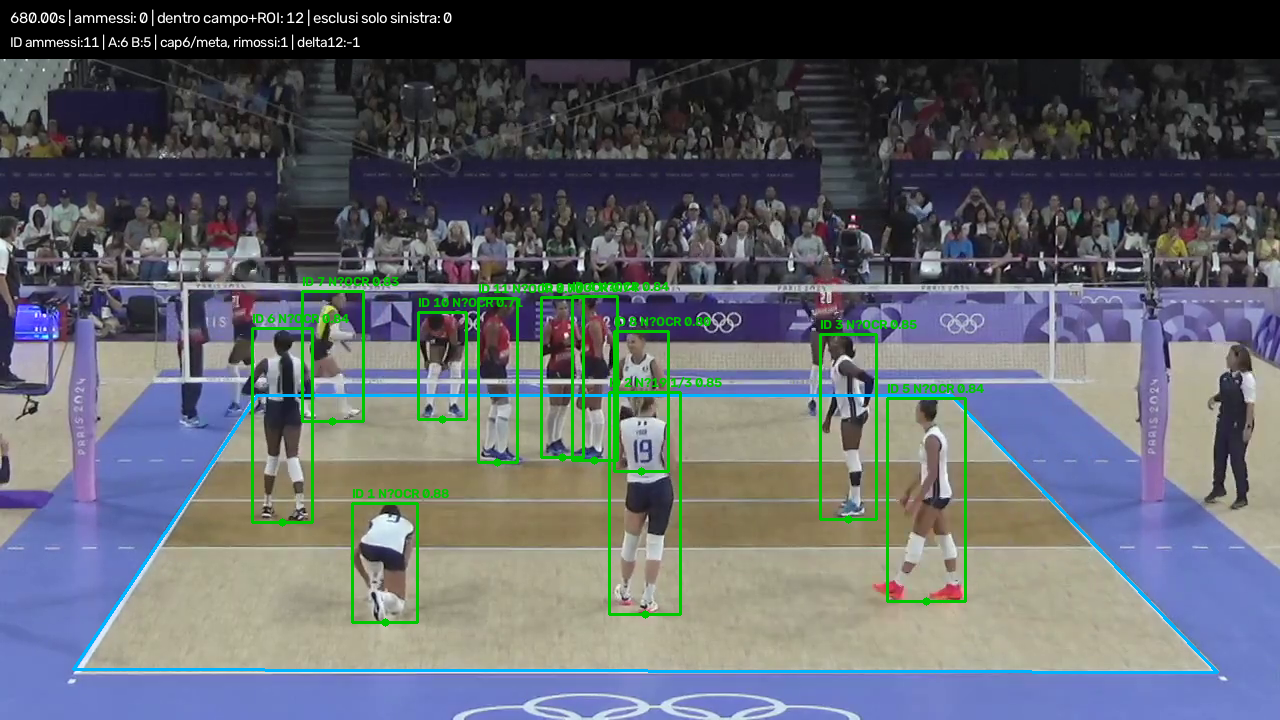

giocatori_frame_020430.png


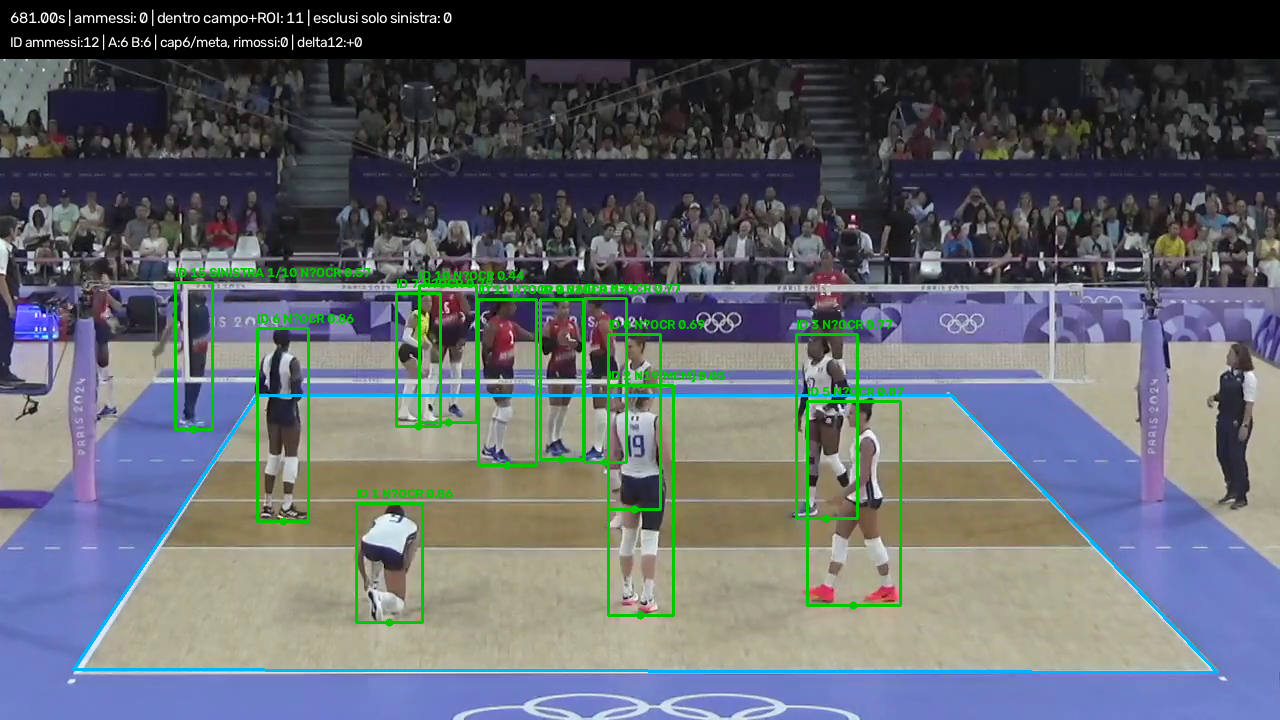

giocatori_frame_020460.png


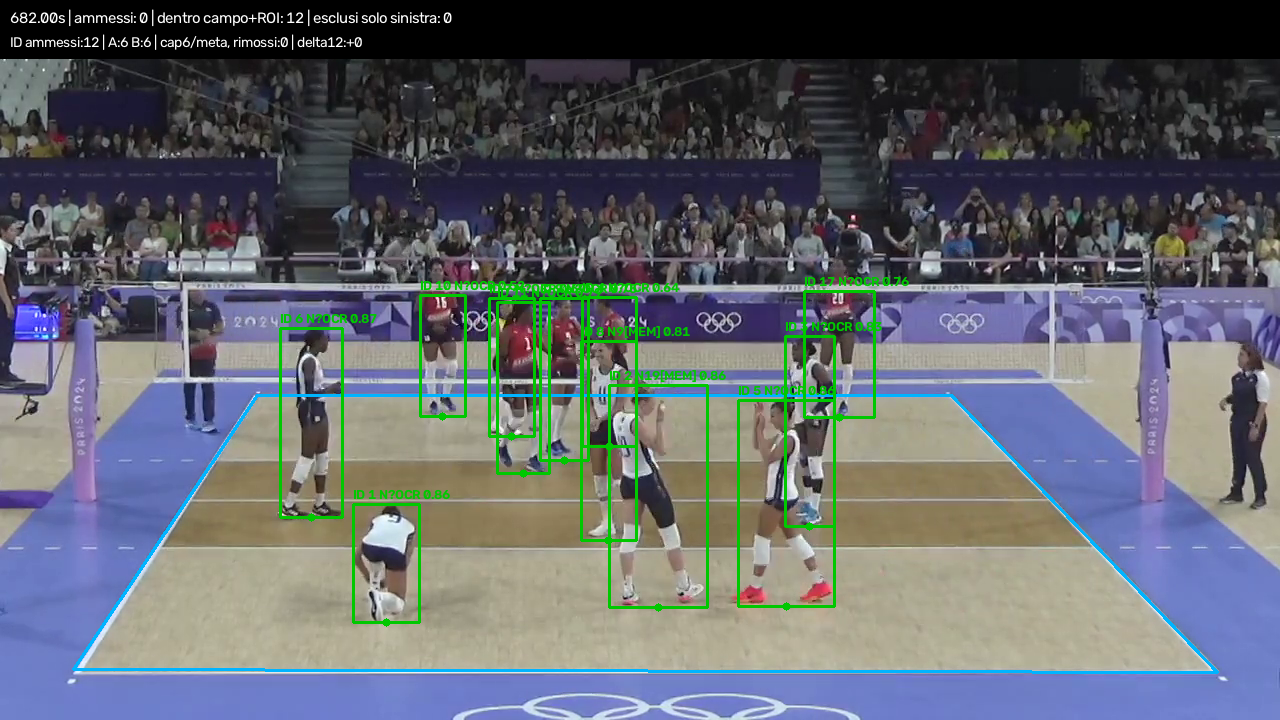

Etichetta N[LETTO]=numero confermato letto nel frame; N[MEM]=valore persistito da letture precedenti; N?=non confermato.
OCR: un tentativo locale per frame osservato ammesso e crop valido; nessun numero viene trasferito tra ID. Coordinate pavimento: proxy bbox, non misura pose.


In [29]:
from IPython.display import display, Image as DisplayImage
for path in sample_paths:
    print(path.name)
    display(DisplayImage(filename=str(path),width=960))
print('Etichetta N[LETTO]=numero confermato letto nel frame; N[MEM]=valore persistito da letture precedenti; N?=non confermato.')
print('OCR: un tentativo locale per frame osservato ammesso e crop valido; nessun numero viene trasferito tra ID. Coordinate pavimento: proxy bbox, non misura pose.')